In [1]:
import numpy as np
import seaborn as sns
import pandas as pd
import logomaker
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"


 1. Read data

In [2]:
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
DATA_PATH = f'{DATA_PATH_BASE}/length_dependent_hmm/per_length_per_kfold_split/' # work laptop
# DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/properites_training/" #!CHANGE for bwv!

In [3]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

ALLELES

['HLA-A*24:02',
 'HLA-DRB3*01:01',
 'HLA-DRB5*01:01',
 'HLA-DRB1*15:01',
 'HLA-A*11:01',
 'HLA-A*01:01',
 'HLA-DRB1*01:01',
 'HLA-B*07:02',
 'HLA-DRB1*04:01',
 'HLA-DPA1*01:03/DPB1*04:01',
 'HLA-A*03:01',
 'HLA-B*27:05',
 'HLA-A*02:01',
 'HLA-DRB1*03:01']

In [4]:
def make_logo_for_data(binders_array, name):
    sns.set_theme(style="white")
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

# 2. Prepare data and weithgs for training
## 2.1 Merge alleles into combinations

In [49]:
# combination_size = len(ALLELES)
# ALLELES = sorted(['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'
#                   ])
ALLELES = sorted([ 'HLA-A*03:01',
                   # 'HLA-A*11:01',
                   #    'HLA-DRB1*01:01'
#                    #'HLA-A*02:01', , 'HLA-A*24:02'
                ])

# ALLELES = sorted(['HLA-DRB1*01:01', 'HLA-DRB3*01:01'])
# ALLELES = sorted(['HLA-DRB1*01:01'])

combination_size = 1
TOTAL_SPLITS = 5
NUM_RUNS = 5
USE_WEIGHTS = True
# TARGET_LENGTHS= [13, 14, 15, 16, 17, 18]

# TARGET_LENGTHS= [15, 17]
# TARGET_LENGTHS= [9,  11]
TARGET_LENGTHS= [9 ]
GROUPS = 5
check_peptides = False

## Motif for train data

C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T


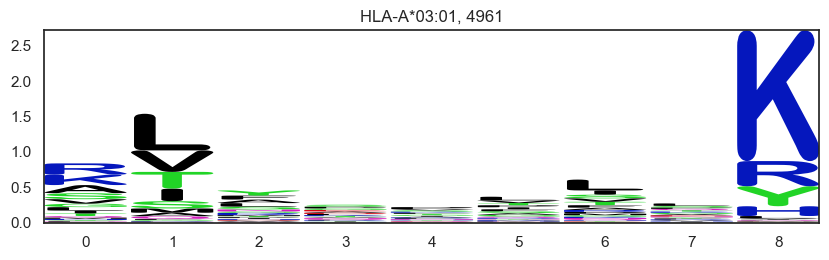

In [50]:
target_allele = ALLELES[0]
target_length = TARGET_LENGTHS[0]
for target_allele in ALLELES:
    peptides = per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]
    make_logo_for_data(peptides, target_allele)

C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T


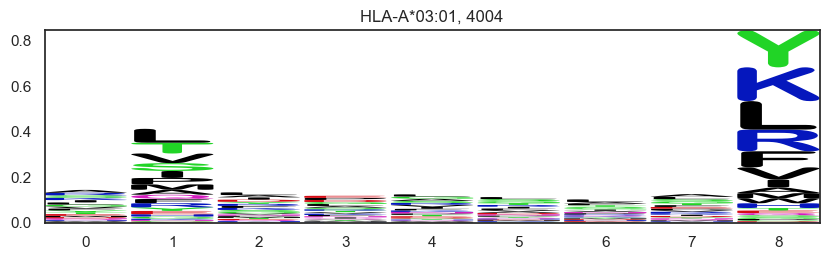

In [51]:
target_allele = ALLELES[0]
target_length = TARGET_LENGTHS[0]


for target_allele in ALLELES:
    peptides = per_allele_per_kfold_per_length_non_binders_train[target_allele][0][target_length]
    make_logo_for_data(peptides, target_allele)

# Make peptide df

In [52]:
#merge_all lengths together

portion = 1000
per_allele_per_group_peptides = {allele_name:{ group_num: 
                           np.concatenate([
                               [peptide for peptide in per_allele_per_kfold_per_length_binders_train[allele_name][0][target_length]][group_num*portion: (group_num+1)* portion]
                               for target_length in TARGET_LENGTHS])
                                             for group_num in range(GROUPS)} for allele_name in ALLELES}

per_allele_per_group_non_binder_peptides = {allele_name:{ group_num: 
                           np.concatenate([[peptide for peptide in per_allele_per_kfold_per_length_non_binders_train[allele_name][0][target_length]] for target_length in TARGET_LENGTHS])
                                             for group_num in range(GROUPS)} for allele_name in ALLELES}


In [53]:
len(per_allele_per_group_peptides[ALLELES[0]][0])

1000

In [54]:

dfs = list()
for allele_name, per_group_peptides in per_allele_per_group_peptides.items():
    for group_num, peptides in per_group_peptides.items():
        
        df = pd.DataFrame({"peptide": peptides, "len": list(map(len, peptides)),"group":group_num, "allele": allele_name})
        # df['src_peptide'] = peptide
        # df['src_len'] = len(peptide)
        # df['allele'] = allele_name
        dfs.append(df)



In [55]:
peptide_df = pd.concat(dfs)

In [56]:
# same for non-binders
dfs = list()
for allele_name, per_group_peptides in per_allele_per_group_non_binder_peptides.items():
    for group_num, peptides in per_group_peptides.items():
        
        df = pd.DataFrame({"peptide": peptides, "len": list(map(len, peptides)),"group":group_num, "allele": allele_name})
        # df['src_peptide'] = peptide
        # df['src_len'] = len(peptide)
        # df['allele'] = allele_name
        dfs.append(df)

peptide_non_binder_df = pd.concat(dfs)

# Prepare set of properties

In [57]:
from protlearn.features import aaindex1

In [58]:
amino_acids = list('ACDEFGHIKLMNPQRSTVWY')
prop_values, prop_names = aaindex1(amino_acids, standardize='zscore')
aa_prop_index = pd.DataFrame(prop_values, columns=prop_names, index=amino_acids).dropna(axis='columns')
all_properties = list(aa_prop_index.columns)
selected_properties = all_properties

In [59]:


transform_dicts = list()
# We want to normalize values of properties
for property_name in selected_properties:
    transform_dicts.append(aa_prop_index[property_name].to_dict())


## AA properties analysis

### First correlation

In [60]:
import seaborn as sns

In [105]:
aa_prop_index

,ANDN920101,ARGP820101,ARGP820102,ARGP820103,BEGF750101,BEGF750102,BEGF750103,BHAR880101,BIGC670101,BIOV880101,...,KARS160113,KARS160114,KARS160115,KARS160116,KARS160117,KARS160118,KARS160119,KARS160120,KARS160121,KARS160122
A,-0.270241,-0.481350,0.246186,0.657435,1.633591,0.156645,-1.696194,-0.863153,-1.429479,-0.077983,...,-1.076537,-1.668147,-1.384723,-1.714199,-1.614728,-0.166380,-2.174062,0.416944,-1.845793,-1.256097
C,0.930829,0.090059,1.070678,0.254924,-1.880311,-0.626582,0.568610,-0.999180,-0.771139,1.394497,...,-1.076537,-0.217768,-0.214535,-0.051945,-0.469058,2.684387,0.628050,0.416944,0.552953,0.972738
D,1.371221,-0.667679,-1.066033,-1.074583,-0.459798,-0.626582,1.195045,1.041225,-0.766945,-0.988596,...,0.009047,-0.254469,-0.214535,-0.259727,-0.039432,0.518489,0.739083,0.416944,0.133296,-0.153195
E,-0.510455,-0.655257,-0.996358,-0.964807,0.624278,-1.279271,-0.925196,0.868099,-0.083446,-1.259843,...,0.009047,0.370812,0.175528,0.363618,0.390193,0.407198,0.756071,0.416944,0.253391,-0.579274
F,0.970864,1.270143,1.151966,1.230708,0.138313,1.527293,-0.925196,-1.394895,1.140983,1.597932,...,1.094630,0.676656,0.955654,0.155836,0.963028,-0.166380,0.451692,0.416944,0.852965,-0.503494
G,-1.791595,-1.152135,-0.555080,-0.489112,-0.796235,-0.626582,1.195045,1.449306,-2.112979,-0.358917,...,-1.981191,-2.007973,-2.359881,-1.714199,-1.972749,-2.306596,-3.049722,0.416944,-2.970275,-1.256097
H,0.850758,-0.481350,-0.764107,-0.891623,0.138313,0.548259,0.134924,-1.283600,0.218468,0.251387,...,0.551839,0.656266,0.955654,0.883072,0.891424,-1.279293,-0.029921,-1.278204,0.133296,-0.659884
I,-1.871667,1.518582,0.559725,0.791605,0.624278,1.527293,-1.696194,0.435286,0.641987,1.229812,...,0.009047,-0.363213,-0.214535,-0.467509,-0.325850,-0.166380,0.074808,-1.187288,-0.226538,-0.003120
K,-0.230205,0.189435,-1.054421,-1.062386,0.138313,-1.279271,0.134924,0.484751,0.771977,-1.598901,...,0.009047,0.846569,0.955654,0.883072,0.175380,-0.020846,-0.293320,0.241955,0.028494,-0.746437
L,-0.990882,0.661468,2.626761,2.328466,1.633591,0.548259,-0.925196,-0.764224,0.641987,1.171688,...,0.009047,-0.363213,-0.214535,-0.467509,-0.325850,-0.166380,0.106331,0.416944,-0.226538,-0.099703


In [61]:
correlations = aa_prop_index.corr().abs()
correlations_array = np.asarray(correlations)
upper = correlations*np.triu(np.ones(correlations.shape), k=1).astype(np.bool)

C:\Users\denkl\AppData\Local\Temp\ipykernel_22284\769499564.py:3: DeprecationWarning: `np.bool` is a deprecated alias for the builtin `bool`. To silence this warning, use `bool` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.bool_` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  upper = correlations*np.triu(np.ones(correlations.shape), k=1).astype(np.bool)


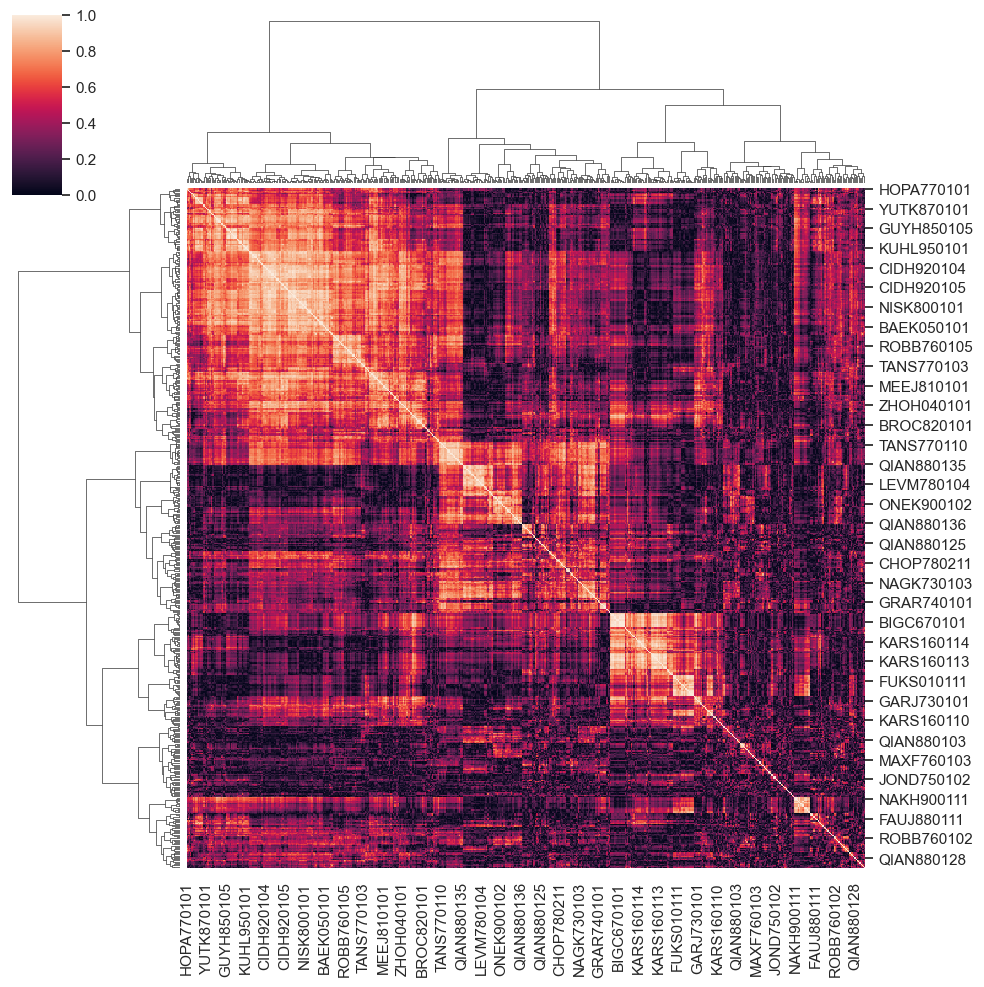

In [62]:
from scipy.spatial import distance
from scipy.cluster import hierarchy

row_linkage = hierarchy.linkage(
    correlations_array, method='ward')

col_linkage = hierarchy.linkage(
    correlations_array.T, method='ward')

result = sns.clustermap(correlations, row_linkage=row_linkage, col_linkage=col_linkage)


In [63]:
np.sum(np.max((upper > 0.9), axis=0))

278

In [64]:
from sklearn.cluster import FeatureAgglomeration
distance_threshold = 6
agglo = FeatureAgglomeration(n_clusters=None, affinity='euclidean', linkage='ward', distance_threshold=distance_threshold)

In [65]:
new_prop_index = agglo.fit_transform(aa_prop_index)
new_prop_index = pd.DataFrame(new_prop_index, index = aa_prop_index.index.values, columns=[f"new_prop_{i}" for i in range(new_prop_index.shape[1])] )


In [66]:
clustered_features = pd.DataFrame({"cluster": agglo.labels_})

clustered_features['prop'] = aa_prop_index.columns
unique_labels_counts = clustered_features.cluster.value_counts().sort_values(ascending=False)
cluster_descriptions = clustered_features.groupby('cluster').agg(lambda x: " ".join(x.values))
cluster_descriptions['len'] = unique_labels_counts
cluster_descriptions.sort_values(by='len', ascending=False)

,prop,len
cluster,,
6,BIGC670101 CHAM820101 CHOC750101 CHOC760101 DA...,27
12,BHAR880101 GUYH850101 KARP850101 KARP850102 KR...,27
31,CHOP780202 CHOP780208 CRAJ730102 GEIM800105 GE...,26
34,BIOV880101 BIOV880102 MANP780101 MEIH800103 NI...,22
4,BROC820101 BROC820102 EISD860101 FAUJ830101 ME...,21
...,...,...
62,RICJ880117 TANS770102,2
46,PRAM820101 KARS160120,2
51,QIAN880127 SUEM840102,2


In [67]:
import numpy as np

from matplotlib import pyplot as plt
from scipy.cluster.hierarchy import dendrogram
from sklearn.datasets import load_iris
from sklearn.cluster import AgglomerativeClustering


def plot_dendrogram(model, **kwargs):
    # Create linkage matrix and then plot the dendrogram

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    # Plot the corresponding dendrogram
    dendrogram(linkage_matrix,leaf_rotation=90,  **kwargs)

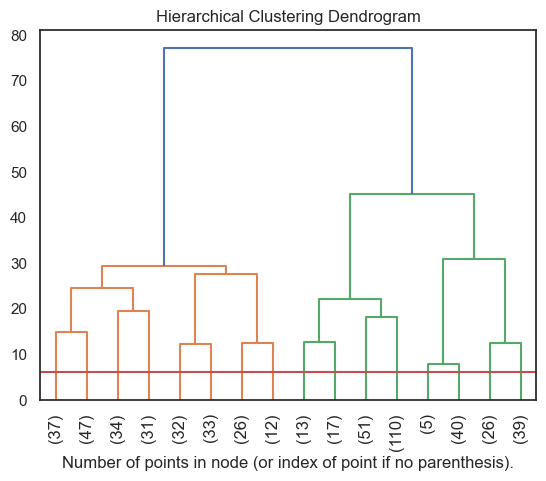

In [68]:
plt.title("Hierarchical Clustering Dendrogram")
# plot the top three levels of the dendrogram
plot_dendrogram(agglo, truncate_mode="level", p=3)
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.axhline(y=distance_threshold, color='r', linestyle='-')
plt.show()

In [69]:
from aaindex.aaindex import aaindex
cluster_num = 30

props = cluster_descriptions.loc[cluster_num].str.split(' ').iloc[0]
for prop_index in props:
    print(prop_index, aaindex[prop_index]['description'])
    values= aaindex[prop_index]['values']
df = aa_prop_index[props]

FAUJ880110 Number of full nonbonding orbitals (Fauchere et al., 1988)
GRAR740102 Polarity (Grantham, 1974)
HOPA770101 Hydration number (Hopfinger, 1971), Cited by Charton-Charton (1982)
HOPT810101 Hydrophilicity value (Hopp-Woods, 1981)
LEVM760101 Hydrophobic parameter (Levitt, 1976)
PRAM900101 Hydrophobicity (Prabhakaran, 1990)
ROSM880101 Side chain hydropathy, uncorrected for solvation (Roseman, 1988)
ROSM880102 Side chain hydropathy, corrected for solvation (Roseman, 1988)
VHEG790101 Transfer free energy to lipophilic phase (von Heijne-Blomberg, 1979)
WOEC730101 Polar requirement (Woese, 1973)
ZIMJ680103 Polarity (Zimmerman et al., 1968)
KUHL950101 Hydrophilicity scale (Kuhn et al., 1995)
PUNT030101 Knowledge-based membrane-propensity scale from 1D_Helix in MPtopo databases (Punta-Maritan, 2003)
PUNT030102 Knowledge-based membrane-propensity scale from 3D_Helix in MPtopo databases (Punta-Maritan, 2003)
KIDA850101 Hydrophobicity-related index (Kidera et al., 1985)
ENGD860101 Hydropho

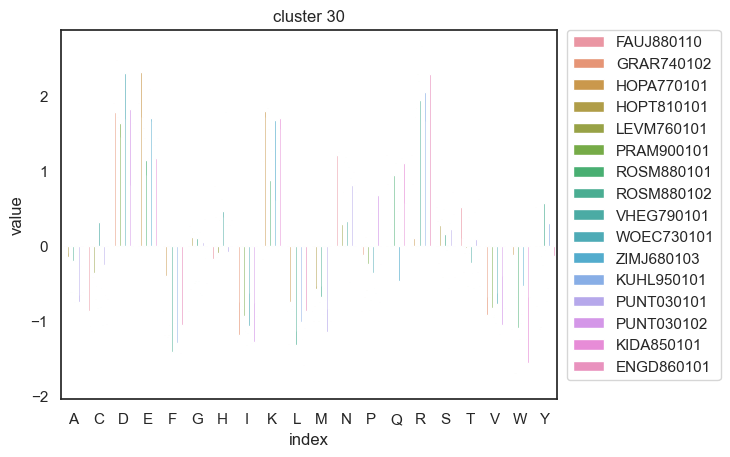

In [70]:
import matplotlib.pyplot as plt

df_melted = pd.melt(df.reset_index() ,id_vars='index' ,value_vars=df.columns ,var_name='property', value_name='value')
ax = sns.barplot(df_melted, x='index', y='value', hue='property')
ax.set_title(f"cluster {cluster_num}")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

C:\Users\denkl\AppData\Local\Temp\ipykernel_22284\2404618074.py:2: DeprecationWarning: `np.bool` is a deprecated alias for the builtin `bool`. To silence this warning, use `bool` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.bool_` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  upper = corr*np.triu(np.ones(corr.shape), k=1).astype(np.bool)


<AxesSubplot: >

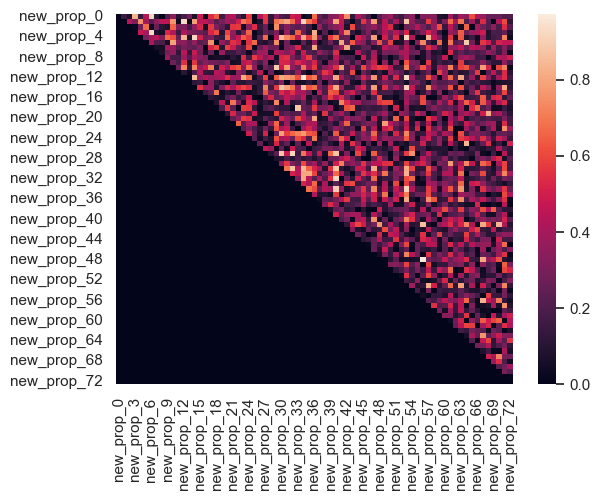

In [71]:
corr = new_prop_index.corr().abs()
upper = corr*np.triu(np.ones(corr.shape), k=1).astype(np.bool)
sns.heatmap(upper)

In [72]:
np.sum(np.max((upper > 0.9), axis=0))

8

<AxesSubplot: >

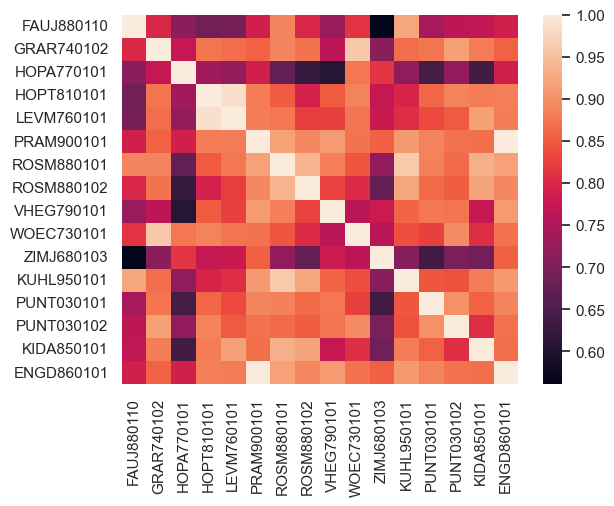

In [73]:
sns.heatmap(df.corr().abs())

In [74]:
correlations['cluster'] = clustered_features['cluster'].values
unique_clusters = correlations['cluster'].unique()

cmap =  sns.color_palette("BuGn_r", len(unique_clusters), as_cmap=True)
row_colors = correlations['cluster'].map(cmap)

## Make new transform dicts

In [75]:

transform_dicts = list()

# We want to normalize values of properties

selected_properties = new_prop_index.columns
for property_name in selected_properties:
    transform_dicts.append(new_prop_index[property_name].to_dict())

# Transform data

In [76]:
#keep intersected lengths only
peptide_df = peptide_df[peptide_df.groupby(['group','len'])['allele'].transform('nunique') == len(ALLELES)]
peptide_non_binder_df = peptide_non_binder_df[peptide_non_binder_df.groupby(['group','len'])['allele'].transform('nunique') == len(ALLELES)]


In [77]:
peptide_df

,peptide,len,group,allele
0,AINGFVLPK,9,0,HLA-A*03:01
1,SLFGGMVLK,9,0,HLA-A*03:01
2,QISAPQSNK,9,0,HLA-A*03:01
3,LTYVQLESR,9,0,HLA-A*03:01
4,GLSTVYLNK,9,0,HLA-A*03:01
...,...,...,...,...
956,FLRATTELR,9,4,HLA-A*03:01
957,VMLGTQLLY,9,4,HLA-A*03:01
958,YMFESKSMK,9,4,HLA-A*03:01
959,HLHPTSTEK,9,4,HLA-A*03:01


In [78]:
def transform_data(peptide_df, transform_dicts):
    print("got df with size", len(peptide_df))
    per_size_transformed_data = dict()
    for group in range(GROUPS):
        for  size in TARGET_LENGTHS:
            columns = list()
            names = list()
            df = peptide_df[(peptide_df['group'] == group)&(peptide_df['len'] == size)].reset_index(drop=True)
            print(f"len of filtered {len(df)}")
            for i, transform_dict in enumerate(transform_dicts):
                for pos in range(size):
                    name = f"{pos}_new_prop_{i}"
                    names.append(name)
                    columns.append(df.peptide.str.get(pos).map(transform_dict).rename(name))
            result_df = pd.concat([df] + columns, axis=1)
            per_size_transformed_data[f"{group}_{size}"] = result_df.copy()
    return per_size_transformed_data






In [79]:
transformed_peptide_dfs = transform_data(peptide_df, transform_dicts)
    
transformed_peptide_non_binder_dfs = transform_data(peptide_non_binder_df, transform_dicts)

got df with size 4961
len of filtered 1000
len of filtered 1000
len of filtered 1000
len of filtered 1000
len of filtered 961
got df with size 20020
len of filtered 4004
len of filtered 4004
len of filtered 4004
len of filtered 4004
len of filtered 4004


In [80]:
transformed_peptide_dfs[f"0_9"]

,peptide,len,group,allele,0_new_prop_0,1_new_prop_0,2_new_prop_0,3_new_prop_0,4_new_prop_0,5_new_prop_0,...,8_new_prop_71,0_new_prop_72,1_new_prop_72,2_new_prop_72,3_new_prop_72,4_new_prop_72,5_new_prop_72,6_new_prop_72,7_new_prop_72,8_new_prop_72
0,AINGFVLPK,9,0,HLA-A*03:01,-1.429296,-0.113714,-0.164471,-1.732990,0.633390,-0.718115,...,0.927217,-1.209077,0.581464,0.929424,0.463100,-0.210342,1.586752,-0.380958,-0.953390,-0.562186
1,SLFGGMVLK,9,0,HLA-A*03:01,-0.859429,-0.229879,0.633390,-1.732990,-1.732990,0.636531,...,0.927217,1.187566,-0.380958,-0.210342,0.463100,0.463100,-1.147157,1.586752,-0.380958,-0.562186
2,QISAPQSNK,9,0,HLA-A*03:01,0.468658,-0.113714,-0.859429,-1.429296,-0.806048,0.468658,...,0.927217,-1.452238,0.581464,1.187566,-1.209077,-0.953390,-1.452238,1.187566,0.929424,-0.562186
3,LTYVQLESR,9,0,HLA-A*03:01,-0.229879,-0.781533,0.949807,-0.718115,0.468658,-0.229879,...,-0.109728,-0.380958,1.419912,0.054447,1.586752,-1.452238,-0.380958,-1.250244,1.187566,0.099781
4,GLSTVYLNK,9,0,HLA-A*03:01,-1.732990,-0.229879,-0.859429,-0.781533,-0.718115,0.949807,...,0.927217,0.463100,-0.380958,1.187566,1.419912,1.586752,0.054447,-0.380958,0.929424,-0.562186
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,AVQQPFINK,9,0,HLA-A*03:01,-1.429296,-0.718115,0.468658,0.468658,-0.806048,0.633390,...,0.927217,-1.209077,1.586752,-1.452238,-1.452238,-0.953390,-0.210342,0.581464,0.929424,-0.562186
996,KLSSNITVK,9,0,HLA-A*03:01,1.109553,-0.229879,-0.859429,-0.859429,-0.164471,-0.113714,...,0.927217,-0.562186,-0.380958,1.187566,1.187566,0.929424,0.581464,1.419912,1.586752,-0.562186
997,KLRLSLSWK,9,0,HLA-A*03:01,1.109553,-0.229879,1.538281,-0.229879,-0.859429,-0.229879,...,0.927217,-0.562186,-0.380958,0.099781,-0.380958,1.187566,-0.380958,1.187566,0.016422,-0.562186
998,RLQLSNDNR,9,0,HLA-A*03:01,1.538281,-0.229879,0.468658,-0.229879,-0.859429,-0.164471,...,-0.109728,0.099781,-0.380958,-1.452238,-0.380958,1.187566,0.929424,-0.256526,0.929424,0.099781


## Prepare negative examples

In [81]:
from mhcgnomes import parse

# decoy data
def defineOrganism(allele_name):
    parse_result = parse(allele_name)
    if parse_result.is_mouse:
        return "Mouse"
    elif parse_result.is_human:
        return "Human"
    else:
        print("organism not found")
        return None


def defineClass(allele_name):
    parse_result = parse(allele_name)
    if parse_result.has_mhc_class:
        if parse_result.is_class1:
            return 'I'
        elif parse_result.is_class2:
            return 'II'
        else:
            print("Not class I or class II???!")
    else:
        print("Result without class")
    return None


per_allele_per_length_decoy_peptides = dict()
for allele_name in ALLELES:
    organism = defineOrganism(allele_name).lower()
    class_to_use = defineClass(allele_name)
    DECOY_DATA_PATH = f"{DATA_PATH_BASE}\decoy\sampled_decoy_data_{organism}_class_{class_to_use}.csv"
    decoy_df = pd.read_csv(DECOY_DATA_PATH)
    decoy_df['length'] = decoy_df['peptide'].str.len()
    per_allele_per_length_decoy_peptides[allele_name] = dict()
    for target_length in TARGET_LENGTHS:
        df = decoy_df[decoy_df.length == target_length]
        assert len(df) > 0
        per_allele_per_length_decoy_peptides[allele_name][target_length] = df.copy()['peptide'].values
        

per_size_decoy_peptides = dict()
for group in range(GROUPS):
    for target_length in TARGET_LENGTHS:
        per_size_decoy_peptides[f"{group}_{target_length}"] =  np.random.choice(np.unique(np.concatenate([value[target_length] for key, value in per_allele_per_length_decoy_peptides.items()
                                                      if key in ALLELES])), len(transformed_peptide_dfs[f"{group}_{target_length}"]))


dfs = list()
for key, peptides in per_size_decoy_peptides.items():
        group_num, length = map(int, key.split("_"))
        
        df = pd.DataFrame({"peptide": peptides, "len": list(map(len, peptides)),"group":group_num, "allele": 'decoy'})
        # df['src_peptide'] = peptide
        # df['src_len'] = len(peptide)
        # df['allele'] = allele_name
        dfs.append(df)
        
    
decoy_df = pd.concat(dfs)


In [82]:
decoy_df

,peptide,len,group,allele
0,FLLDEAPGA,9,0,decoy
1,NPTGAEFDP,9,0,decoy
2,SQKKNTAAS,9,0,decoy
3,WNHETQTLV,9,0,decoy
4,VTPEQIEEA,9,0,decoy
...,...,...,...,...
956,RGLWCEKGV,9,4,decoy
957,HNAARKDDS,9,4,decoy
958,ADLEEGEPA,9,4,decoy
959,KFMPIVYTP,9,4,decoy


In [83]:
peptide_df

,peptide,len,group,allele
0,AINGFVLPK,9,0,HLA-A*03:01
1,SLFGGMVLK,9,0,HLA-A*03:01
2,QISAPQSNK,9,0,HLA-A*03:01
3,LTYVQLESR,9,0,HLA-A*03:01
4,GLSTVYLNK,9,0,HLA-A*03:01
...,...,...,...,...
956,FLRATTELR,9,4,HLA-A*03:01
957,VMLGTQLLY,9,4,HLA-A*03:01
958,YMFESKSMK,9,4,HLA-A*03:01
959,HLHPTSTEK,9,4,HLA-A*03:01


In [84]:

transformed_decoy_dfs = transform_data(decoy_df, transform_dicts)




got df with size 4961
len of filtered 1000
len of filtered 1000
len of filtered 1000
len of filtered 1000
len of filtered 961


In [85]:
NON_BINDERS_INSTEAD_OF_DECOY = False

if NON_BINDERS_INSTEAD_OF_DECOY:
    transformed_decoy_dfs = transformed_peptide_non_binder_df




In [86]:
from protlearn.dimreduction import tree_importance
from sklearn.utils import shuffle




total_dfs = {f"{group_num}_{target_length}": pd.concat([transformed_peptide_dfs[f"{group_num}_{target_length}"], transformed_decoy_dfs[f"{group_num}_{target_length}"]]) for target_length in TARGET_LENGTHS for group_num in range(GROUPS)}

for key in total_dfs.keys():
    total_dfs[key]['label'] = total_dfs[key].allele.map({allele_name: i for i, allele_name in enumerate(['decoy'] + ALLELES)})
# total_df = peptide_df

# SVD Part

## First just SVD without correlation within dataset

In [90]:
from sklearn.decomposition import TruncatedSVD, PCA
import seaborn as sns
not_feature_columns = ['label', 'peptide', 'len', 'allele', 'group']


per_size_algo_object = dict()
per_size_exp_variance = dict()
per_size_component_matrix = dict()
per_size_component_formula = dict()
per_size_component_df = dict()
per_size_result_df = dict()
per_size_transformed_df = dict()

for key in total_dfs.keys():
    df_to_analyze = total_dfs[key]
    X = df_to_analyze.drop(columns=not_feature_columns).values
    y = df_to_analyze.label.values
    X, y = shuffle(X, y, random_state=0)
    

    svd = TruncatedSVD(n_components=10)
    pca = PCA(n_components=10)
    algo_object = svd
    algo_object.fit(X)
    exp_variance = algo_object.explained_variance_
    variance_df = pd.DataFrame({"component": np.arange(0, len(algo_object.explained_variance_ratio_)), "variance_ratio":algo_object.explained_variance_ratio_, "variance": algo_object.explained_variance_})
    # save component formulas
    component_matrix = algo_object.components_
    feature_names = list(df_to_analyze.columns.drop(not_feature_columns))
    component_formulas = list()
    for i in range(len(component_matrix)):
        
        component_formulas.extend([f"\n {i}: \n\t", " ".join([
            "%+0.3f * %s" % (coef, feat)
            for coef, feat in zip(component_matrix[i], feature_names) if coef > 0.1 or coef < -0.1
        ])])
                                 
    component_formula = ''.join(component_formulas)
    components_df = pd.DataFrame(component_matrix, columns=feature_names)
        
    #transform data    
    result_df = pd.DataFrame(algo_object.transform(X))
    result_df['label'] = y
    
    
    X = df_to_analyze.drop(columns=not_feature_columns).values
    y = df_to_analyze.label.values
    pep =  df_to_analyze.peptide.values
    transformed_df = pd.DataFrame(algo_object.transform(X))
    transformed_df['peptide'] = pep
    transformed_df['label'] = y
    transformed_df['len'] = df_to_analyze['len'].values
    transformed_df['allele'] = df_to_analyze['allele'].values
    
    per_size_algo_object[key] = algo_object
    per_size_exp_variance[key] = variance_df
    
    per_size_component_matrix[key] = component_matrix
    per_size_component_formula[key] = component_formula
    per_size_component_df[key] = components_df
    per_size_result_df[key] = result_df
    per_size_transformed_df[key] = transformed_df

    
    


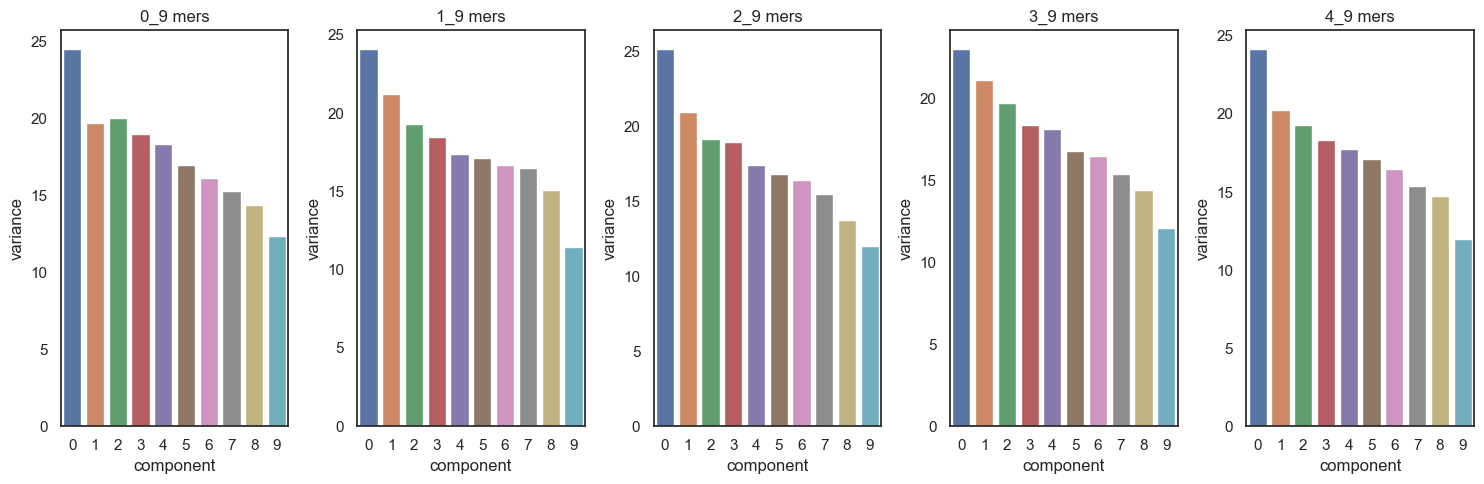

In [91]:
subsets = total_dfs.keys()
fig, axes = plt.subplots(ncols=len(subsets), figsize=(15, 5))

for i, key in enumerate(subsets):
    sns.barplot(data=per_size_exp_variance[key], x ="component", y="variance", ax=axes[i]).set_title(f'{key} mers')
# sns.barplot(data=per_size_exp_variance[11], x ="component", y="variance", ax=axes[1]).set_title('11 mers')
plt.tight_layout()


In [92]:
print(per_size_component_formula['1_9'])


 0: 
	+0.108 * 8_new_prop_0 +0.120 * 8_new_prop_12 +0.161 * 1_new_prop_15 +0.140 * 8_new_prop_23 +0.154 * 8_new_prop_26 -0.118 * 8_new_prop_27 +0.121 * 8_new_prop_30 +0.180 * 8_new_prop_32 -0.120 * 8_new_prop_34 -0.121 * 8_new_prop_40 +0.103 * 8_new_prop_43 +0.114 * 8_new_prop_44 -0.112 * 8_new_prop_47 -0.112 * 8_new_prop_50 -0.131 * 8_new_prop_51 -0.100 * 8_new_prop_65 +0.122 * 1_new_prop_71
 1: 
	-0.136 * 6_new_prop_1 +0.106 * 6_new_prop_2 -0.128 * 6_new_prop_4 -0.114 * 6_new_prop_5 +0.143 * 6_new_prop_10 +0.103 * 7_new_prop_10 +0.133 * 6_new_prop_12 +0.120 * 6_new_prop_14 -0.122 * 6_new_prop_15 -0.115 * 6_new_prop_17 +0.129 * 6_new_prop_29 -0.112 * 6_new_prop_31 -0.133 * 6_new_prop_34 -0.110 * 6_new_prop_40 -0.101 * 4_new_prop_41 -0.112 * 6_new_prop_41 -0.113 * 6_new_prop_47 -0.102 * 4_new_prop_48 +0.111 * 6_new_prop_50 -0.144 * 6_new_prop_53 +0.102 * 4_new_prop_56 -0.104 * 6_new_prop_57 +0.131 * 6_new_prop_61 -0.110 * 6_new_prop_63 +0.108 * 4_new_prop_67 +0.102 * 6_new_prop_67 -0.

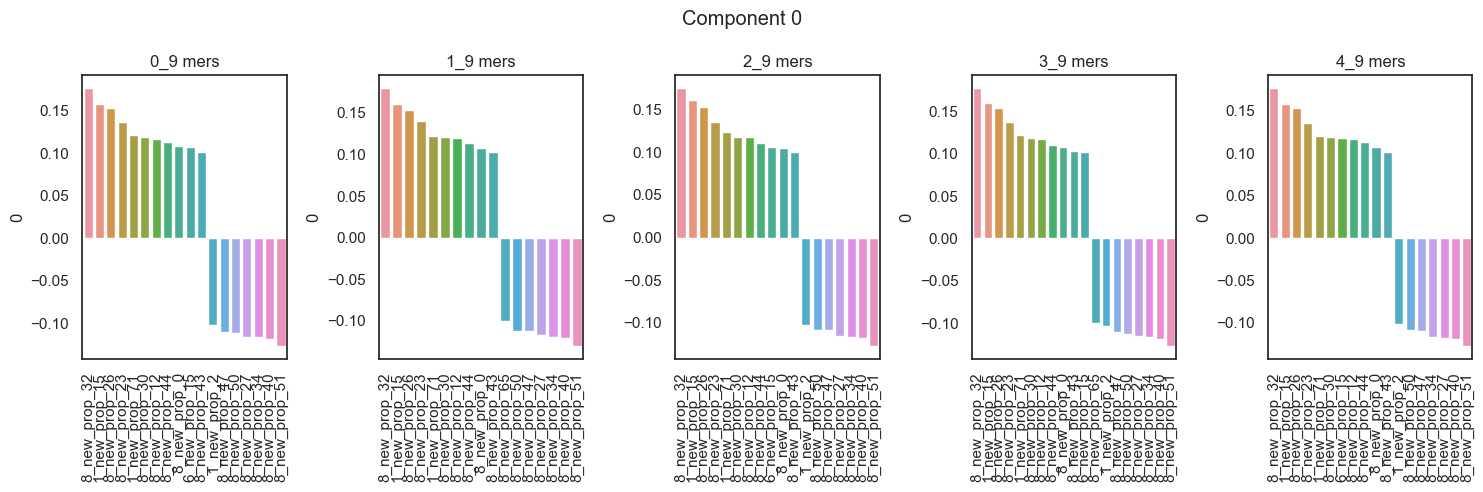

In [95]:


def plot_component(components_df,component_num, ax):
    T_components = components_df.T.sort_values(by=component_num, ascending=False)
    T_components = T_components[(T_components[component_num] > 0.1) | (T_components[component_num] < -0.1)]
    ax = sns.barplot(data =T_components, x=T_components.index, y=component_num, ax=ax)
    ax.tick_params(axis='x', rotation=90)
    return ax
fig, axes = plt.subplots(ncols=len(subsets), figsize=(15, 5))

component_num = 0

for i, key in enumerate(subsets):
    plot_component(per_size_component_df[key], component_num, axes[i]).set_title(f"{key} mers")   
fig.suptitle(f"Component {component_num}")
plt.tight_layout()
 

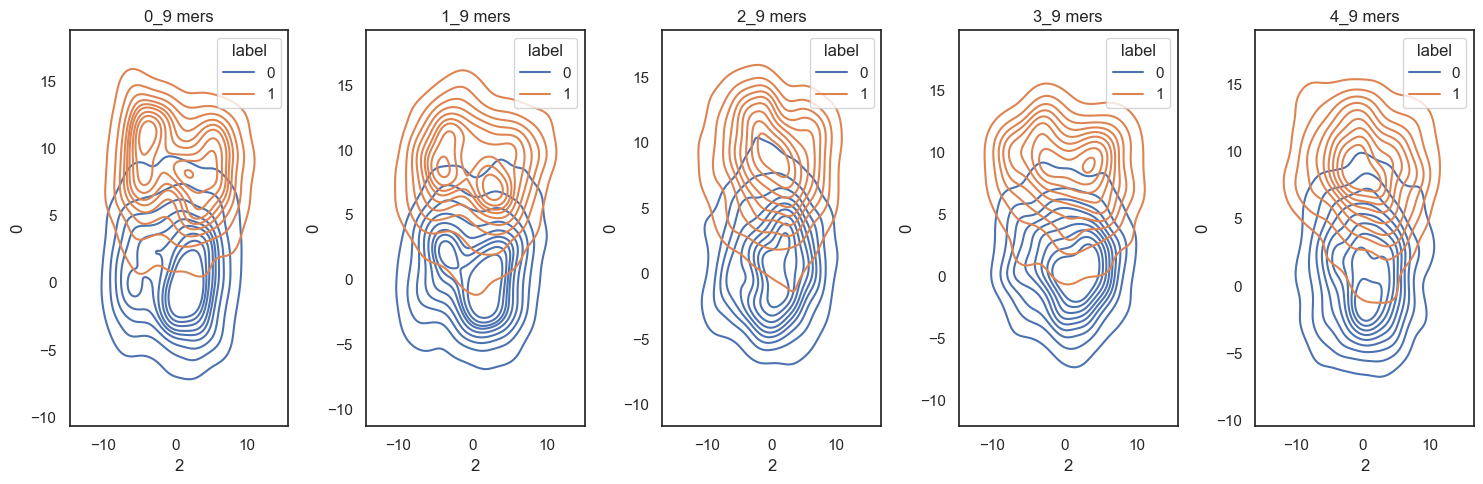

In [96]:
fig, axes = plt.subplots(ncols=len(subsets), figsize=(15, 5))

x=2
y=0
for i, key in enumerate(subsets):
    tr_df1 = per_size_transformed_df[key]
    sns.kdeplot(data=tr_df1, x=x , y=y, hue='label', ax = axes[i]).set_title(f"{key} mers")

plt.tight_layout()

C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a n

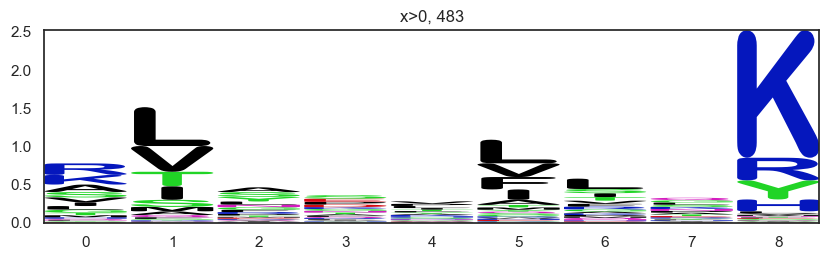

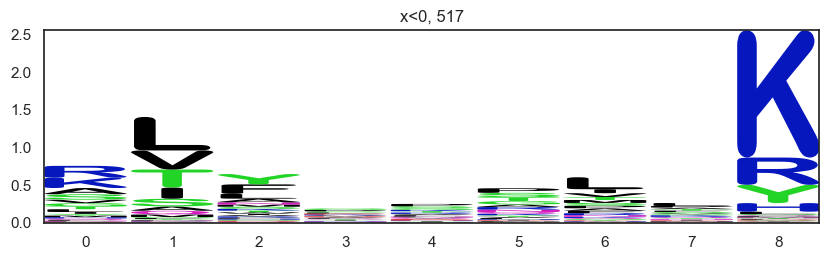

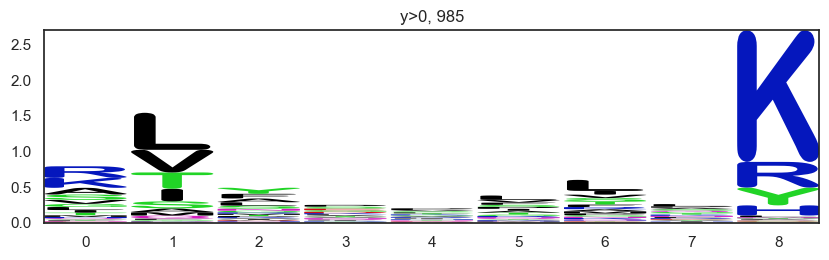

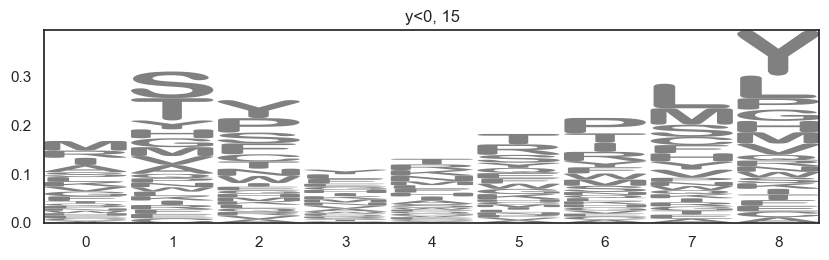

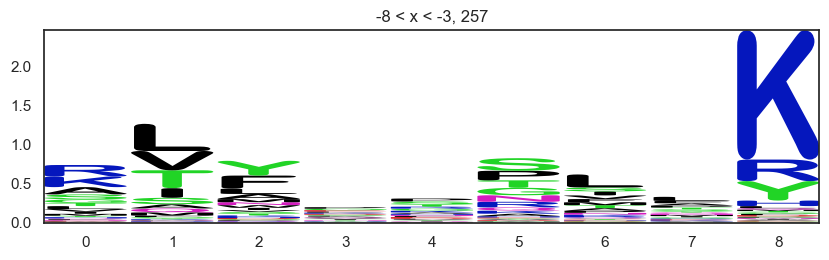

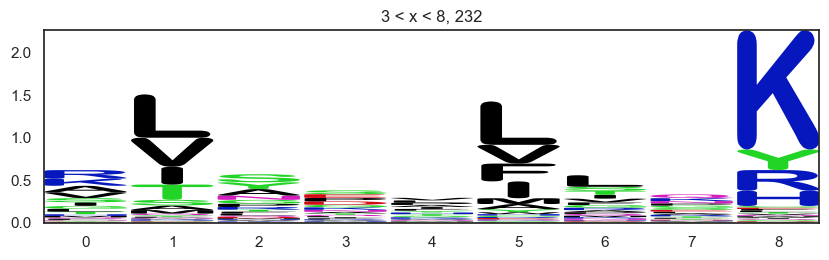

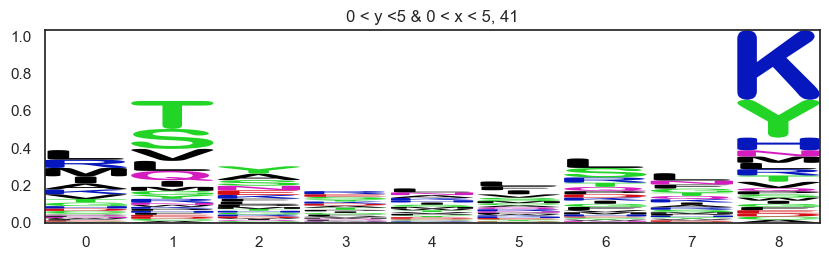

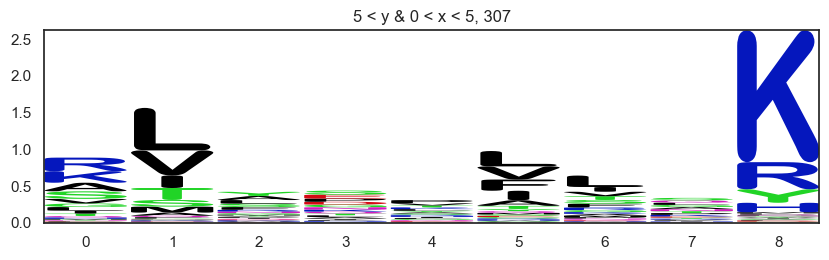

In [510]:
transformed_df = tr_df1[tr_df1.label == 1]
df1 = transformed_df[(transformed_df[x] > 0) ]
df2 = transformed_df[(transformed_df[x] < 0)]
df3 = transformed_df[(transformed_df[y] > 0) ]
df4 = transformed_df[(transformed_df[y] < 0)]
df5 = transformed_df[(transformed_df[x] > -8) & (transformed_df[x] < -3)]
df6 = transformed_df[(transformed_df[x] > 3) & (transformed_df[x] < 8)]
df7 = transformed_df[(transformed_df[y] > 0) & (transformed_df[y] < 5) & (transformed_df[x] > 0) & (transformed_df[x] < 5)]
df8 = transformed_df[(transformed_df[y] > 5)   & (transformed_df[x] > 0) & (transformed_df[x] < 5)]

# df8 = transformed_df
peptides = df1['peptide']
make_logo_for_data(peptides, "x>0")
peptides = df2['peptide']
make_logo_for_data(peptides, "x<0")

peptides = df3['peptide']
make_logo_for_data(peptides, "y>0")
peptides = df4['peptide']
make_logo_for_data(peptides, "y<0")
peptides = df5['peptide']
make_logo_for_data(peptides, "-8 < x < -3")
peptides = df6['peptide']
make_logo_for_data(peptides, "3 < x < 8")
peptides = df7['peptide']
make_logo_for_data(peptides, "0 < y <5 & 0 < x < 5")

peptides = df8['peptide']
make_logo_for_data(peptides, "5 < y & 0 < x < 5")

In [511]:
df_to_analyze

,peptide,len,group,allele,0_new_prop_0,1_new_prop_0,2_new_prop_0,3_new_prop_0,4_new_prop_0,5_new_prop_0,...,0_new_prop_72,1_new_prop_72,2_new_prop_72,3_new_prop_72,4_new_prop_72,5_new_prop_72,6_new_prop_72,7_new_prop_72,8_new_prop_72,label
0,KLRQPFFQK,9,2,HLA-A*03:01,1.109553,-0.229879,1.538281,0.468658,-0.806048,0.633390,...,-0.562186,-0.380958,0.099781,-1.452238,-0.953390,-0.210342,-0.210342,-1.452238,-0.562186,1
1,RLYERLFQH,9,2,HLA-A*03:01,1.538281,-0.229879,0.949807,0.107572,1.538281,-0.229879,...,0.099781,-0.380958,0.054447,-1.250244,0.099781,-0.380958,-0.210342,-1.452238,0.579846,1
2,GTHPTTTYK,9,2,HLA-A*03:01,-1.732990,-0.781533,0.740862,-0.806048,-0.781533,-0.781533,...,0.463100,1.419912,0.579846,-0.953390,1.419912,1.419912,1.419912,0.054447,-0.562186,1
3,MVNHSTYYV,9,2,HLA-A*03:01,0.636531,-0.718115,-0.164471,0.740862,-0.859429,-0.781533,...,-1.147157,1.586752,0.929424,0.579846,1.187566,1.419912,0.054447,0.054447,1.586752,1
4,RVLPLLLAY,9,2,HLA-A*03:01,1.538281,-0.718115,-0.229879,-0.806048,-0.229879,-0.229879,...,0.099781,1.586752,-0.380958,-0.953390,-0.380958,-0.380958,-0.380958,-1.209077,0.054447,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,YKSSGTPRS,9,2,decoy,0.949807,1.109553,-0.859429,-0.859429,-1.732990,-0.781533,...,0.054447,-0.562186,1.187566,1.187566,0.463100,1.419912,-0.953390,0.099781,1.187566,0
996,DHTNKKAQY,9,2,decoy,-0.478462,0.740862,-0.781533,-0.164471,1.109553,1.109553,...,-0.256526,0.579846,1.419912,0.929424,-0.562186,-0.562186,-1.209077,-1.452238,0.054447,0
997,DRFRLHDLL,9,2,decoy,-0.478462,1.538281,0.633390,1.538281,-0.229879,0.740862,...,-0.256526,0.099781,-0.210342,0.099781,-0.380958,0.579846,-0.256526,-0.380958,-0.380958,0
998,TGQLSGIAE,9,2,decoy,-0.781533,-1.732990,0.468658,-0.229879,-0.859429,-1.732990,...,1.419912,0.463100,-1.452238,-0.380958,1.187566,0.463100,0.581464,-1.209077,-1.250244,0


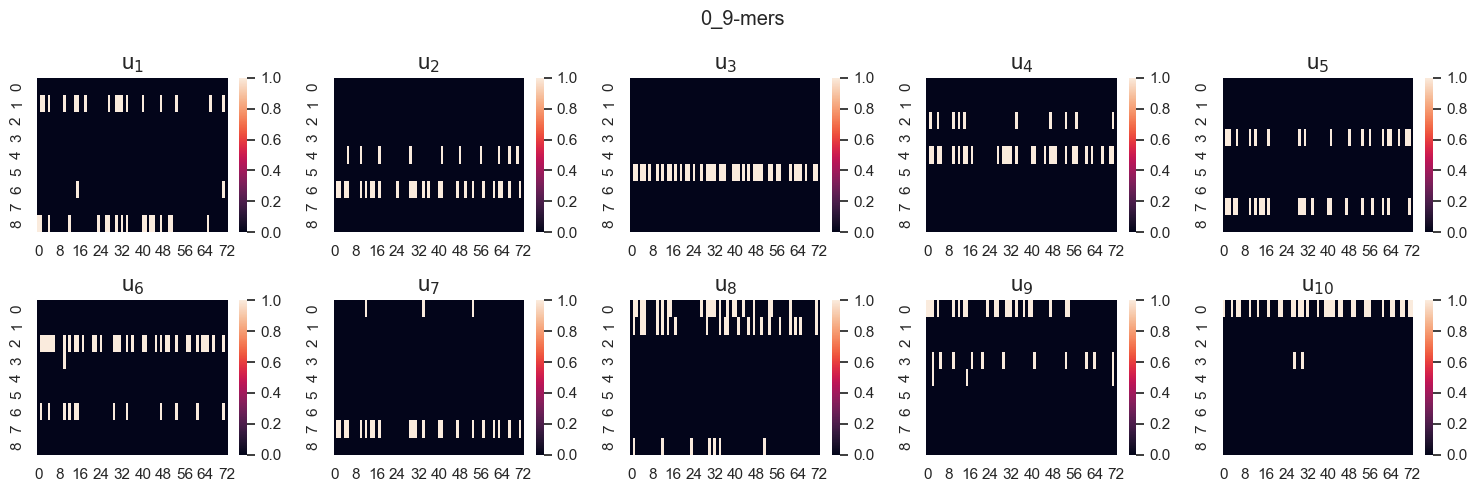

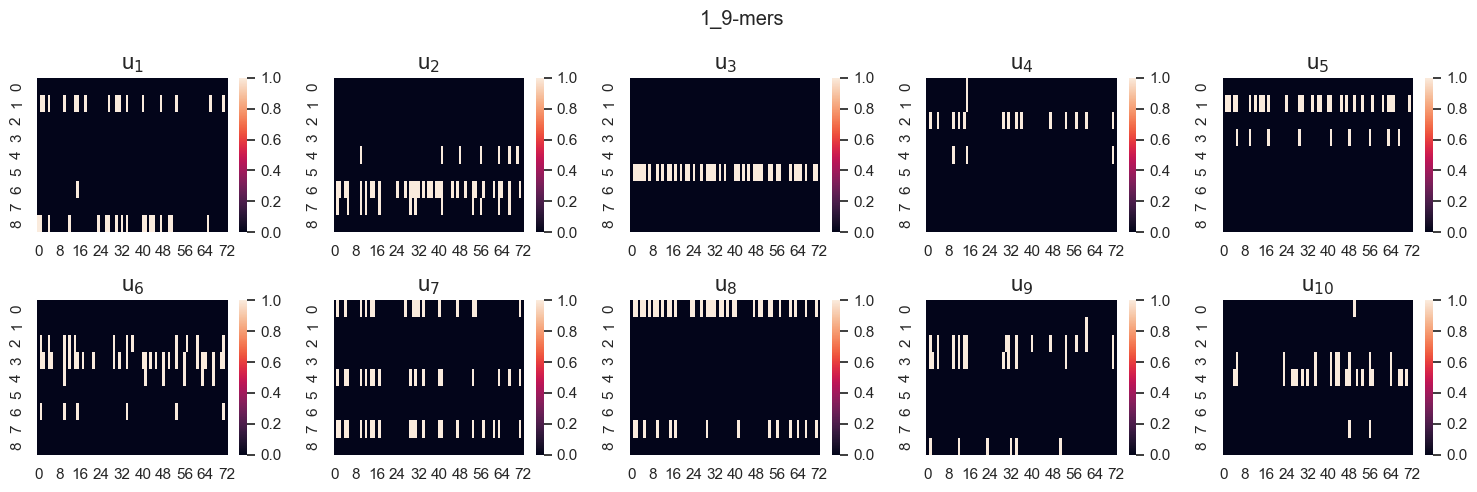

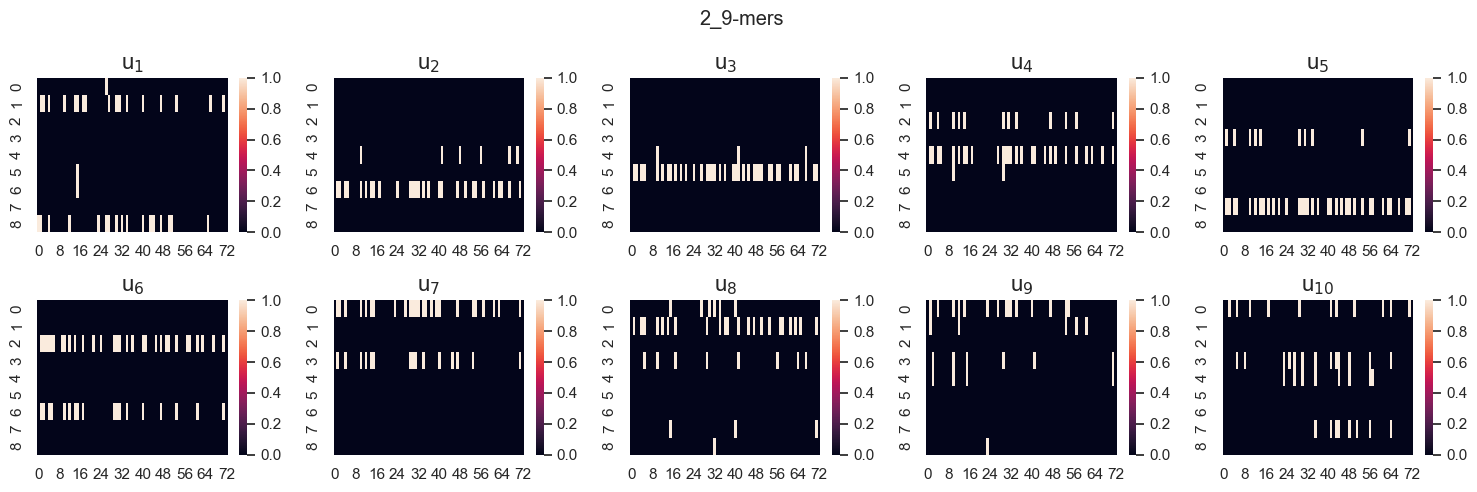

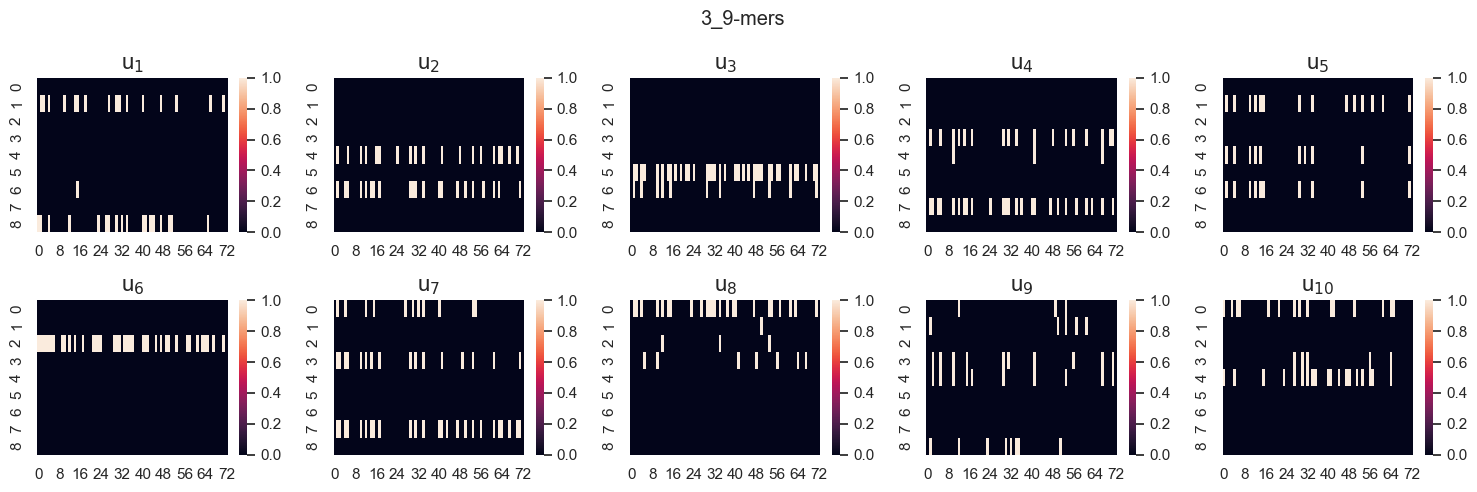

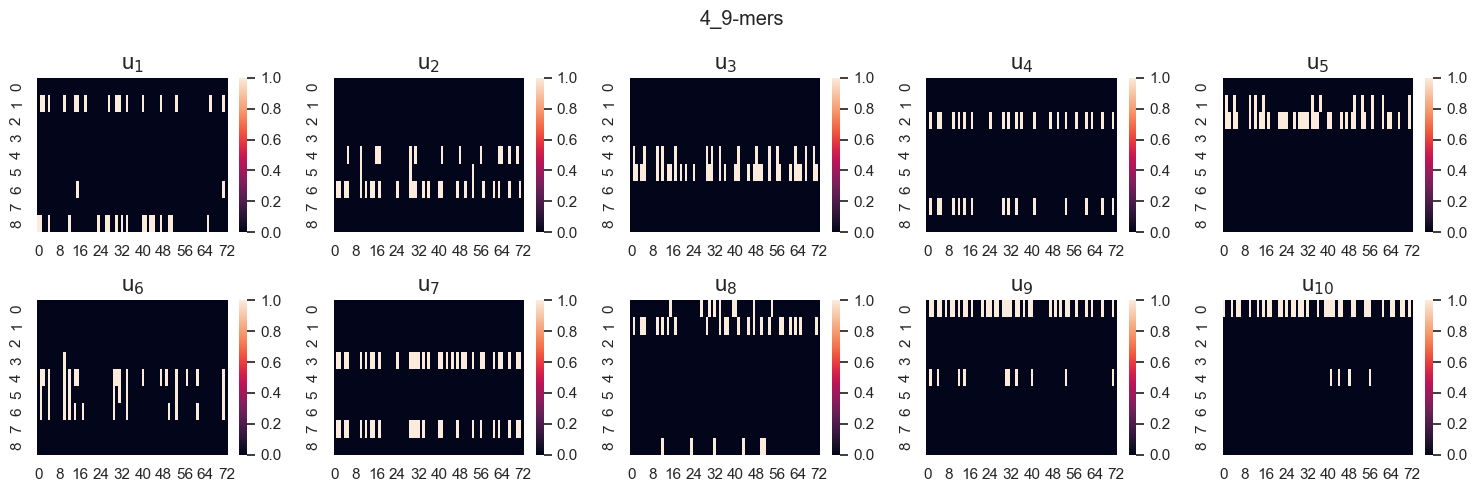

In [98]:
import matplotlib.pyplot as plt


def plot_u_vectors(total_dfs, key):
    df_to_analyze = total_dfs[key]
    U = per_size_component_matrix[key]

    nrows = int(len(U) / 2)

    fig, axes = plt.subplots( 2,nrows, figsize=(15,5))
    prop_nums = np.array(df_to_analyze.drop(columns=not_feature_columns).columns.str.split('_').map(lambda x: x[-1]).unique().astype(int))
    threshold = None
    threshold = 0.08
    target_length = int(key.split("_")[1])


    for i, ax in enumerate(fig.axes):
        prop_position_matrix = np.zeros((target_length, max(prop_nums) + 1))

        for prop_name, value in zip(df_to_analyze.drop(columns=not_feature_columns).columns, U[i, :]):
            m_j = int(prop_name.split('_')[-1])
            m_i = int(prop_name.split('_')[0])
            prop_position_matrix[m_i][m_j] = value

        if threshold:
            df = (np.abs(prop_position_matrix) > threshold)
        else:
            df = prop_position_matrix
        sns.heatmap(df, ax=ax).set_title(f"u$_{{{i+1}}}$", fontsize=16)
        # axes[i // 4, i % 4].imshow(U[:, i].reshape((73,9)))
    fig.suptitle(f"{key}-mers")
    plt.tight_layout()

for i, key in enumerate(subsets):
    plot_u_vectors(total_dfs, key)


In [99]:
dfs = [pd.DataFrame(per_size_component_matrix[key], columns=total_dfs[key].drop(columns=not_feature_columns).columns)
       for key in subsets]


In [100]:
dfs[0]

,0_new_prop_0,1_new_prop_0,2_new_prop_0,3_new_prop_0,4_new_prop_0,5_new_prop_0,6_new_prop_0,7_new_prop_0,8_new_prop_0,0_new_prop_1,...,8_new_prop_71,0_new_prop_72,1_new_prop_72,2_new_prop_72,3_new_prop_72,4_new_prop_72,5_new_prop_72,6_new_prop_72,7_new_prop_72,8_new_prop_72
0,0.001499,-0.041517,-0.010270,-0.041911,-0.020233,-0.038031,-0.020664,-0.020706,0.108196,-0.029817,...,0.055981,-0.001226,0.040136,-0.006162,-0.001104,0.006208,0.014249,0.009630,-0.002356,-0.040728
1,-0.015701,-0.026665,-0.024226,-0.031087,-0.061824,-0.047463,-0.047710,-0.045271,-0.006594,-0.012962,...,0.005618,0.004940,0.004117,0.007296,-0.005368,-0.018841,0.014992,0.020506,0.004430,-0.013831
2,-0.007387,0.007034,0.014055,-0.005905,0.003326,-0.043446,-0.006716,-0.001931,0.010377,0.015537,...,-0.002366,0.012222,-0.012919,-0.000468,-0.004016,-0.000325,-0.011549,-0.002352,0.017922,-0.005878
3,0.007594,0.012352,-0.033049,-0.028272,0.014269,0.008614,-0.001178,0.005582,-0.000249,0.011117,...,0.014094,-0.006170,-0.019337,0.012541,0.003979,0.024788,-0.000103,-0.011316,-0.000675,-0.000717
4,0.001694,0.017056,0.001134,0.056012,-0.021624,0.020495,-0.008687,0.022653,0.010523,0.052498,...,0.005073,0.002966,-0.020550,0.012423,-0.012633,-0.003091,0.008202,0.015009,-0.009104,-0.006194
5,-0.008387,0.004275,-0.068489,0.003962,-0.012349,-0.011731,0.012787,-0.014530,0.005264,0.005888,...,-0.016642,0.000163,-0.006187,0.030970,0.007603,-0.007644,0.014459,-0.014607,-0.003960,0.006211
6,-0.005306,-0.017173,-0.042011,-0.035871,-0.023116,0.011218,-0.009607,0.023062,-0.011151,-0.078115,...,-0.019350,-0.003820,0.005861,0.007404,-0.005751,0.005986,-0.003086,-0.002393,-0.000578,0.003509
7,-0.039875,-0.052439,-0.056634,-0.018438,-0.008852,-0.010863,-0.024732,-0.013148,0.025203,0.103169,...,0.002882,-0.015527,0.037753,-0.005674,-0.001730,0.018201,-0.008911,0.018366,-0.015837,-0.024544
8,0.080694,-0.020085,0.009788,0.023445,-0.013643,-0.012711,-0.002428,0.002117,0.018788,-0.112302,...,-0.000062,-0.017096,0.007121,-0.000247,-0.016426,-0.009567,-0.002161,0.005308,0.000446,-0.025196
9,-0.213656,-0.006488,-0.040817,-0.047384,-0.004291,-0.003202,-0.023938,-0.026603,-0.015539,-0.013669,...,-0.003814,0.080940,0.016942,-0.002445,0.023021,0.019049,0.011246,0.024078,0.019478,0.011444


In [101]:
concat_df = pd.concat(dfs).reset_index(drop=True)
corr_df = concat_df.T.corr()

Text(0.5, 1.0, 'correlation of U vectors')

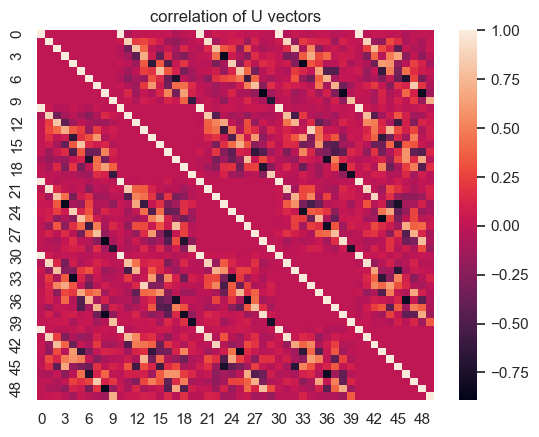

In [106]:
sns.heatmap(corr_df).set_title(f"correlation of U vectors")

Text(0.5, 1.0, 'Abs correlation of U vectors with threshold 0.6')

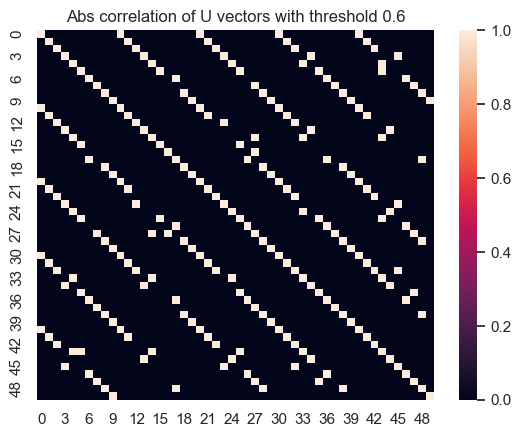

In [104]:
threshold = 0.6
sns.heatmap(corr_df.abs() > threshold).set_title(f"Abs correlation of U vectors with threshold {threshold}")

## Another try with numpy library

In [176]:
from sklearn.utils.extmath import safe_sparse_dot

not_feature_columns = ['label', 'peptide', 'len', 'allele']


per_size_algo_object = dict()
per_size_exp_variance = dict()
per_size_component_matrix = dict()
per_size_component_formula = dict()
per_size_component_df = dict()
per_size_result_df = dict()
per_size_transformed_df = dict()

for target_length in TARGET_LENGTHS:
    df_to_analyze = total_dfs[target_length]
    X = df_to_analyze.drop(columns=not_feature_columns).values
    y = df_to_analyze.label.values
    X, y = shuffle(X, y, random_state=0)
    
    
    U , s, VT  = np.linalg.svd(X)
    variance_df = pd.DataFrame({"component": np.arange(0, len(s)), "sigma":s})

    # save component formulas
    component_matrix = VT[:10]
    feature_names = list(df_to_analyze.columns.drop(not_feature_columns))
    components_df = pd.DataFrame(component_matrix, columns=feature_names)
        
    #transform data    
    X = df_to_analyze.drop(columns=not_feature_columns).values
    y = df_to_analyze.label.values
    pep =  df_to_analyze.peptide.values
    
    transformed_X = safe_sparse_dot(X, VT.T)
    transformed_df = pd.DataFrame(transformed_X[:, :10])
    transformed_df['label'] = y
    transformed_df['peptide'] = pep
    transformed_df['label'] = y
    transformed_df['len'] = df_to_analyze['len'].values
    transformed_df['allele'] = df_to_analyze['allele'].values
    
    
    per_size_exp_variance[target_length] = variance_df
    per_size_component_matrix[target_length] = component_matrix
    per_size_component_df[target_length] = components_df
    per_size_transformed_df[target_length] = transformed_df


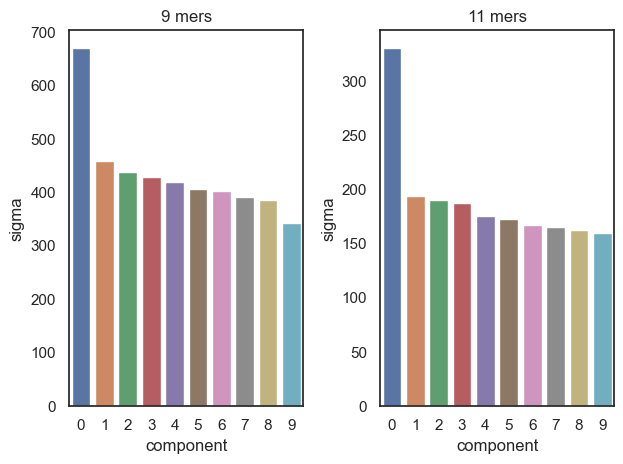

In [177]:
fig, axes = plt.subplots(ncols=2)

sns.barplot(data=per_size_exp_variance[9][:10], x ="component", y="sigma", ax=axes[0]).set_title('9 mers')
sns.barplot(data=per_size_exp_variance[11][:10], x ="component", y="sigma", ax=axes[1]).set_title('11 mers')
plt.tight_layout()

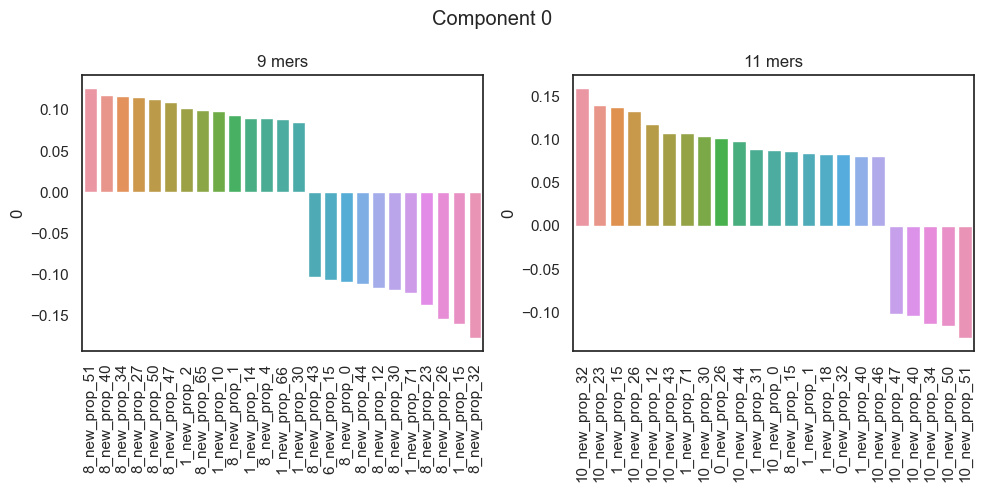

In [178]:
fig, axes = plt.subplots(ncols=2, figsize=(10, 5))

component_num = 0
plot_component(per_size_component_df[9], component_num, axes[0]).set_title("9 mers")   
plot_component(per_size_component_df[11], component_num, axes[1]).set_title("11 mers")     
fig.suptitle(f"Component {component_num}")
plt.tight_layout()

In [192]:
tr_df1

,0,1,2,3,4,5,6,7,8,9,peptide,label,len,allele
0,13.336347,-2.344049,-3.007321,7.821963,-4.490185,4.357714,-0.776909,2.846711,-1.809451,5.143301,AINGFVLPK,1,9,HLA-A*03:01
1,13.667787,-2.056514,-0.110309,-5.227891,3.536217,-5.115119,5.541262,-1.397465,-1.604080,5.882706,SLFGGMVLK,1,9,HLA-A*03:01
2,8.703794,11.207321,-0.136011,0.672232,2.660751,4.956477,-1.135676,-3.679884,0.547871,-0.911055,QISAPQSNK,1,9,HLA-A*03:01
3,3.847882,3.945190,-5.074193,-0.768445,2.428720,0.849451,-3.257687,8.923284,1.925310,-2.240920,LTYVQLESR,1,9,HLA-A*03:01
4,10.877570,-3.289010,-0.848643,5.482608,-3.356998,5.549847,-0.307632,-1.915924,2.415845,7.082969,GLSTVYLNK,1,9,HLA-A*03:01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9917,-1.893763,2.965872,2.531164,1.582243,-6.806841,-1.581058,2.059875,0.509776,1.997140,-1.389567,TSHSCSEEG,0,9,decoy
9918,7.306369,-3.419552,3.934813,5.421047,-0.031784,0.948763,5.653283,-3.264074,2.901506,2.704965,NVSSFEWVK,0,9,decoy
9919,0.034830,3.428922,-7.847140,3.467061,-1.868418,-3.090278,1.019182,-4.079465,3.468734,-7.890824,RKRECLDES,0,9,decoy
9920,7.244821,-1.504837,-1.197942,-3.176500,-7.414955,0.757907,1.446517,0.780095,0.578398,-3.635978,KECGKAFSR,0,9,decoy


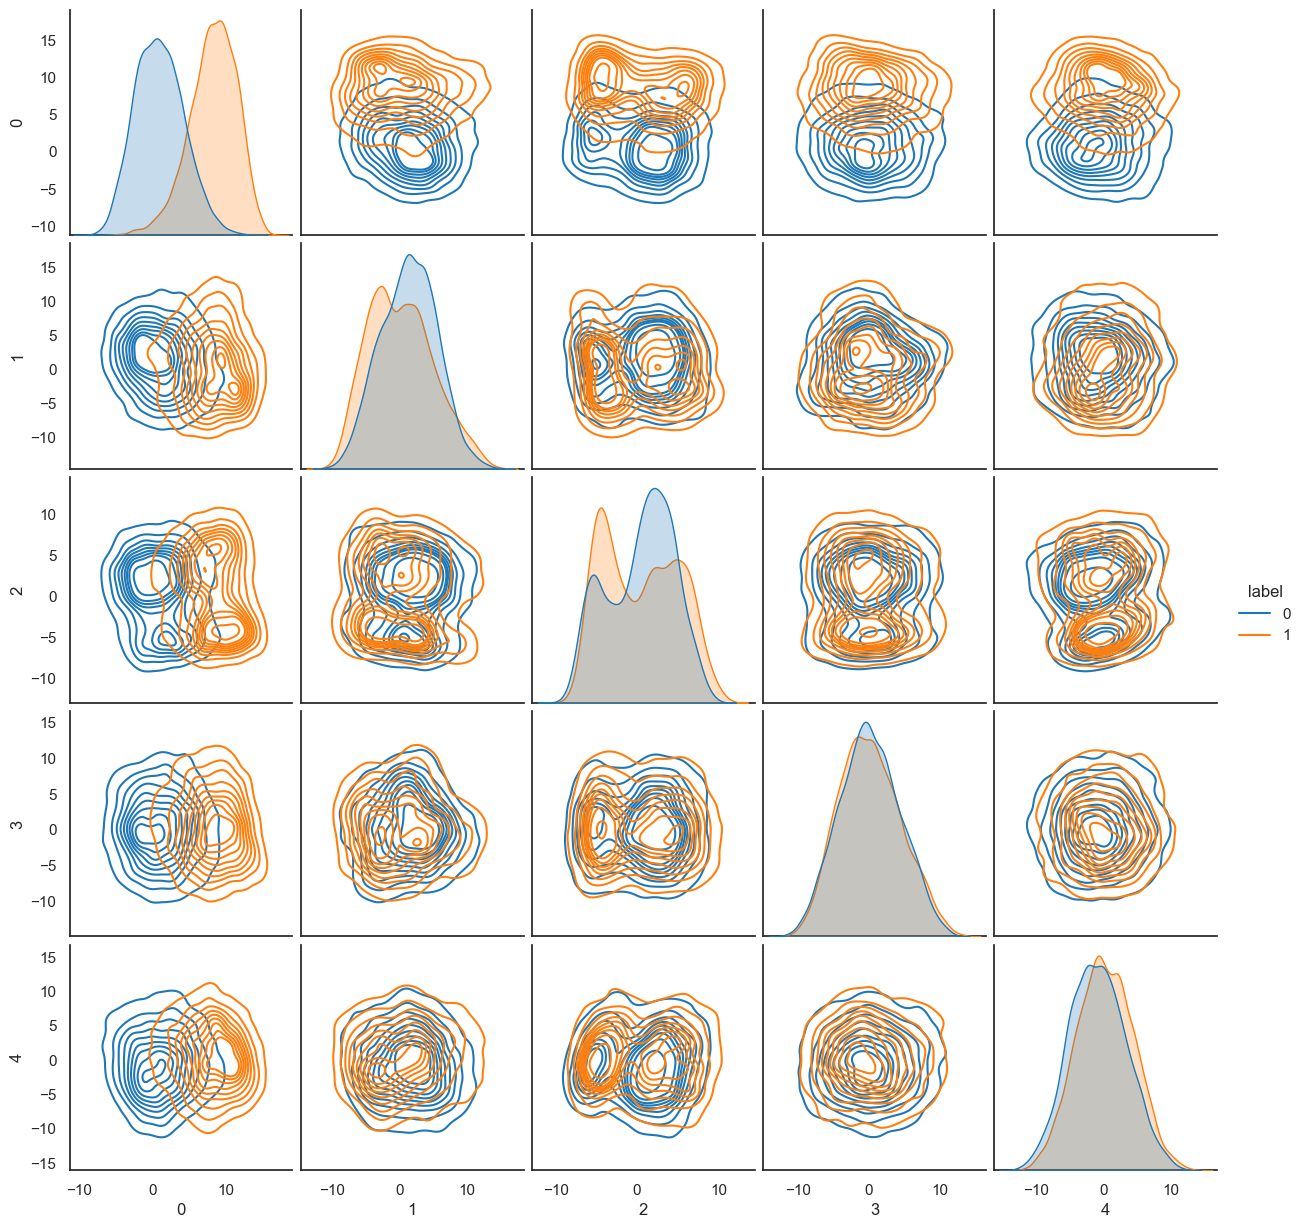

In [197]:
tr_df1 = per_size_transformed_df[9]
sns.pairplot(data=tr_df1[[0,1,2,3,4,'label']], hue='label', palette="tab10", kind='kde' )

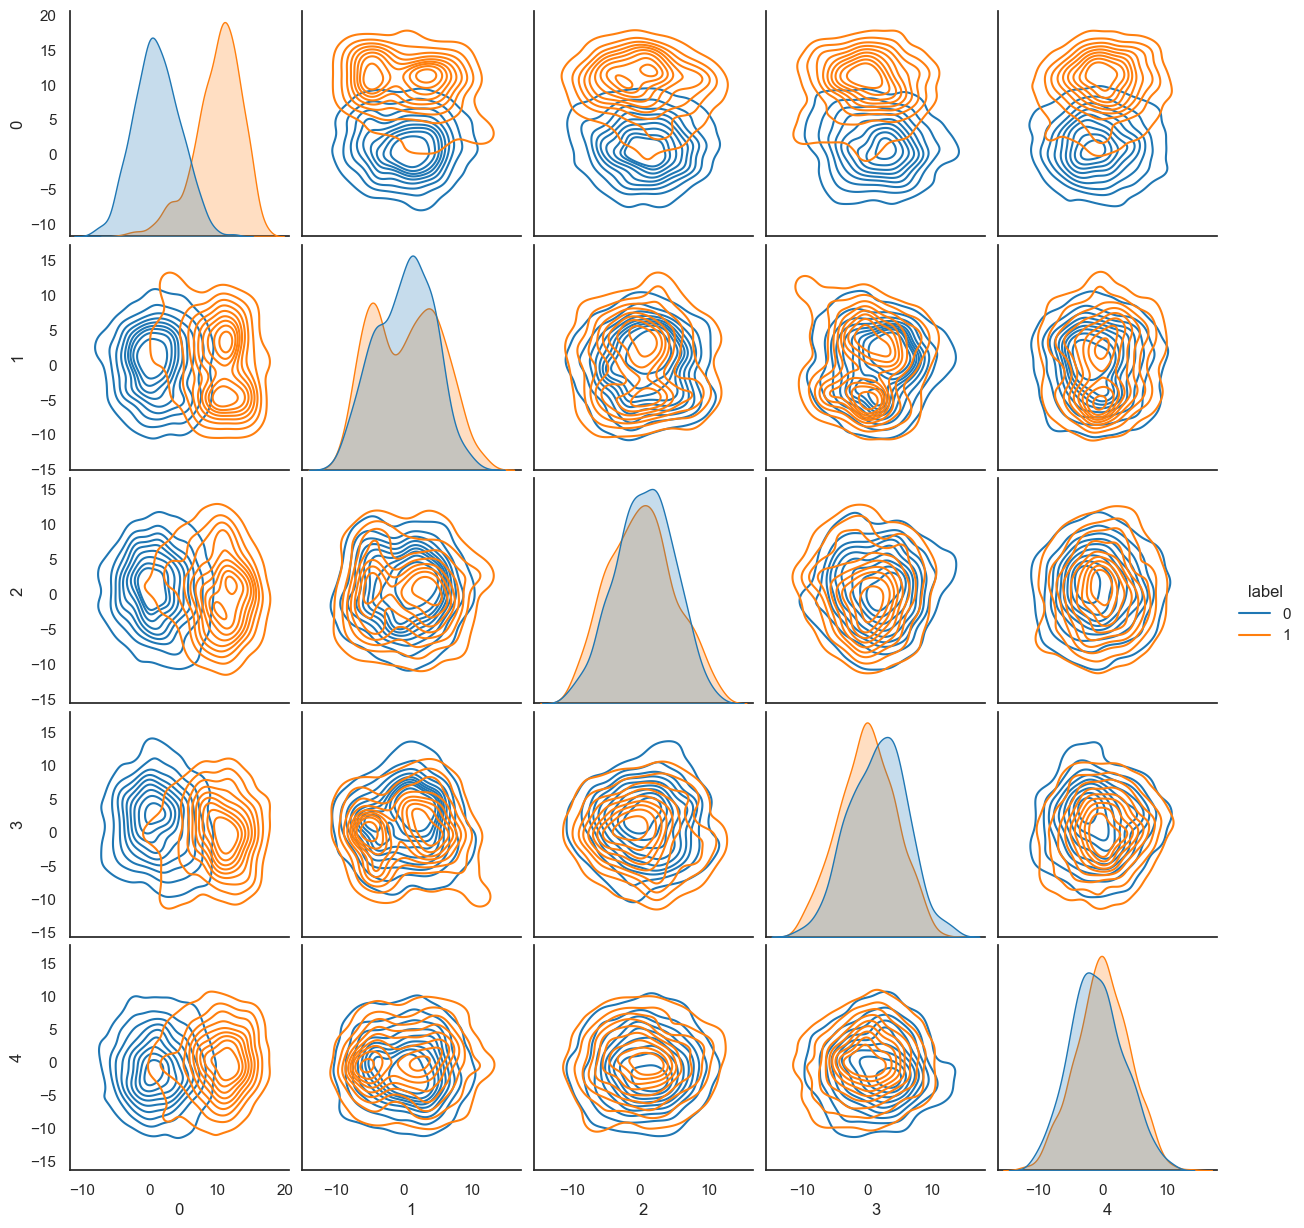

In [198]:
tr_df2 = per_size_transformed_df[11]
sns.pairplot(data=tr_df2[[0,1,2,3,4,'label']], hue='label', palette="tab10", kind='kde' )

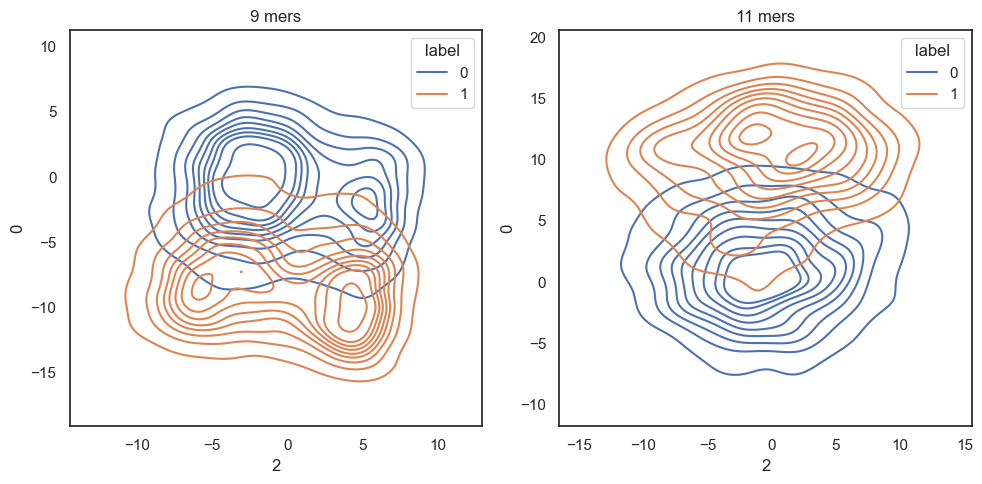

In [181]:
fig, axes = plt.subplots(ncols=2, figsize=(10, 5))

x=2
y=0
tr_df1 = per_size_transformed_df[9]
sns.kdeplot(data=tr_df1, x=x , y=y, hue='label', ax = axes[0]).set_title("9 mers")

tr_df2 = per_size_transformed_df[11]
sns.kdeplot(data=tr_df2, x=x , y=y, hue='label', ax = axes[1]).set_title("11 mers")
plt.tight_layout()

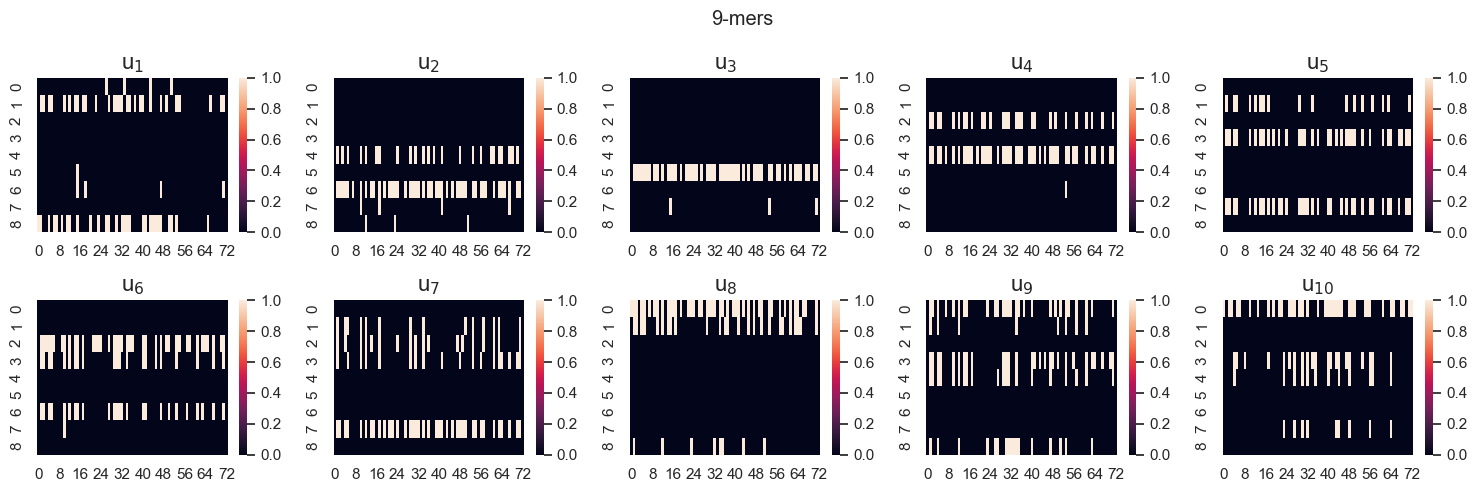

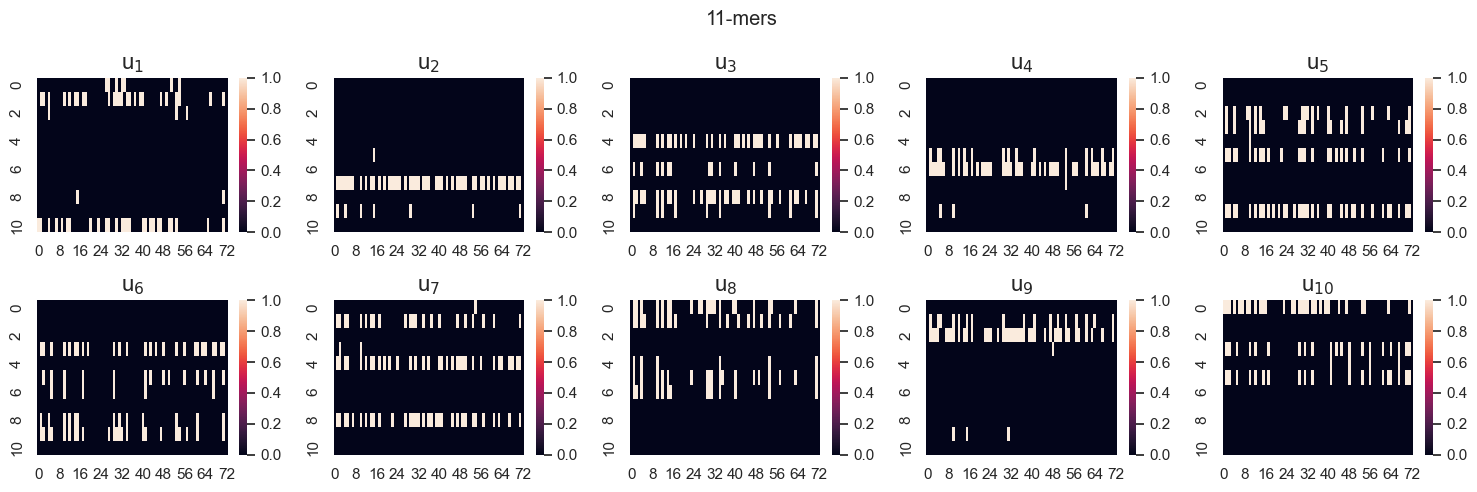

In [180]:
plot_u_vectors(total_dfs, 9)
plot_u_vectors(total_dfs, 11)

## If we add preprocessing step where we remove correlated 

In [124]:
from sklearn.decomposition import TruncatedSVD, PCA
import seaborn as sns
not_feature_columns = ['label', 'peptide', 'len', 'allele', 'group']


per_size_algo_object = dict()
per_size_exp_variance = dict()
per_size_component_matrix = dict()
per_size_component_formula = dict()
per_size_component_df = dict()
per_size_result_df = dict()
per_size_transformed_df = dict()
per_size_data_df = dict()

for key in total_dfs.keys():
    df_to_analyze = total_dfs[key]
    X = df_to_analyze.drop(columns=not_feature_columns).values
    y = df_to_analyze.label.values
    X, y = shuffle(X, y, random_state=0)
    
    corr = np.absolute(np.corrcoef(X, rowvar=False))
    upper = corr*np.triu(np.ones(corr.shape), k=1).astype(bool)
    to_drop = [column for column in range(upper.shape[1]) \
                   if any(upper[:,column] > 0.9)]
    print(f"need to delete {len(to_drop)} properties")
    to_drop_columns = df_to_analyze.columns[to_drop]
    df_to_analyze = df_to_analyze.drop(columns=to_drop_columns)
    X = df_to_analyze.drop(columns=not_feature_columns).values
    y = df_to_analyze.label.values
    X, y = shuffle(X, y, random_state=0)


    svd = TruncatedSVD(n_components=10)
    pca = PCA(n_components=10)
    algo_object = svd
    algo_object.fit(X)
    exp_variance = algo_object.explained_variance_
    variance_df = pd.DataFrame({"component": np.arange(0, len(algo_object.explained_variance_ratio_)), "variance_ratio":algo_object.explained_variance_ratio_, "variance": algo_object.explained_variance_})
    # save component formulas
    component_matrix = algo_object.components_
    feature_names = list(df_to_analyze.columns.drop(not_feature_columns))
    component_formulas = list()
    for i in range(len(component_matrix)):
        
        component_formulas.extend([f"\n {i}: \n\t", " ".join([
            "%+0.3f * %s" % (coef, feat)
            for coef, feat in zip(component_matrix[i], feature_names) if coef > 0.1 or coef < -0.1
        ])])
                                 
    component_formula = ''.join(component_formulas)
    components_df = pd.DataFrame(component_matrix, columns=feature_names)
        
    #transform data    
    result_df = pd.DataFrame(algo_object.transform(X))
    result_df['label'] = y
    
    
    X = df_to_analyze.drop(columns=not_feature_columns).values
    y = df_to_analyze.label.values
    pep =  df_to_analyze.peptide.values
    transformed_df = pd.DataFrame(algo_object.transform(X))
    transformed_df['peptide'] = pep
    transformed_df['label'] = y
    transformed_df['len'] = df_to_analyze['len'].values
    transformed_df['allele'] = df_to_analyze['allele'].values
    
    per_size_algo_object[key] = algo_object
    per_size_exp_variance[key] = variance_df
    per_size_data_df[key] = df_to_analyze
    per_size_component_matrix[key] = component_matrix
    per_size_component_formula[key] = component_formula
    per_size_component_df[key] = components_df
    per_size_result_df[key] = result_df
    per_size_transformed_df[key] = transformed_df


need to delete 95 properties
need to delete 96 properties
need to delete 96 properties
need to delete 93 properties
need to delete 97 properties


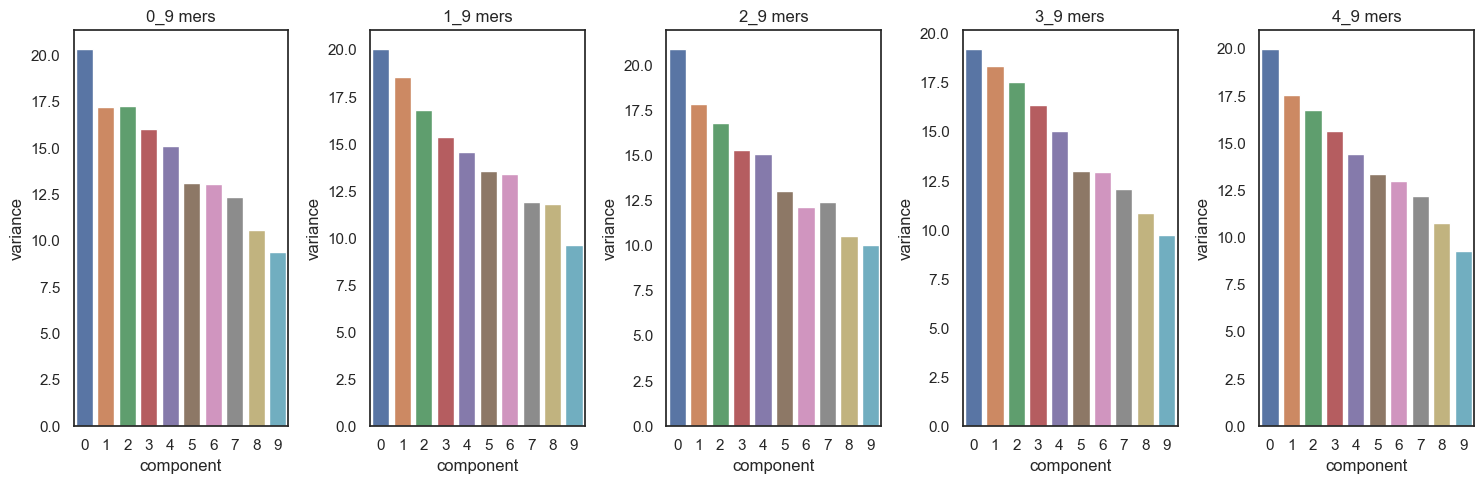

In [125]:
subsets = total_dfs.keys()
fig, axes = plt.subplots(ncols=len(subsets), figsize=(15, 5))

for i, key in enumerate(subsets):
    sns.barplot(data=per_size_exp_variance[key], x ="component", y="variance", ax=axes[i]).set_title(f'{key} mers')
# sns.barplot(data=per_size_exp_variance[11], x ="component", y="variance", ax=axes[1]).set_title('11 mers')
plt.tight_layout()


In [126]:
print(per_size_component_formula['1_9'])


 0: 
	+0.119 * 8_new_prop_0 -0.108 * 8_new_prop_1 -0.103 * 1_new_prop_2 -0.104 * 8_new_prop_4 +0.133 * 8_new_prop_12 +0.168 * 1_new_prop_15 +0.108 * 6_new_prop_15 +0.103 * 1_new_prop_18 +0.156 * 8_new_prop_23 +0.169 * 8_new_prop_26 -0.130 * 8_new_prop_27 +0.134 * 8_new_prop_30 +0.198 * 8_new_prop_32 -0.133 * 8_new_prop_34 -0.134 * 8_new_prop_40 +0.114 * 8_new_prop_43 +0.125 * 8_new_prop_44 -0.125 * 8_new_prop_47 -0.123 * 8_new_prop_50 -0.144 * 8_new_prop_51 -0.110 * 8_new_prop_65 +0.126 * 1_new_prop_71
 1: 
	-0.135 * 6_new_prop_1 -0.111 * 7_new_prop_1 +0.106 * 6_new_prop_2 -0.133 * 6_new_prop_4 +0.134 * 6_new_prop_10 +0.135 * 7_new_prop_10 +0.132 * 6_new_prop_12 +0.109 * 7_new_prop_12 +0.123 * 6_new_prop_14 -0.130 * 6_new_prop_15 -0.107 * 6_new_prop_17 -0.111 * 7_new_prop_17 +0.116 * 7_new_prop_29 +0.106 * 6_new_prop_30 -0.133 * 6_new_prop_34 -0.106 * 7_new_prop_34 -0.114 * 6_new_prop_40 -0.102 * 4_new_prop_41 -0.119 * 7_new_prop_41 -0.118 * 6_new_prop_47 -0.105 * 4_new_prop_48 +0.112

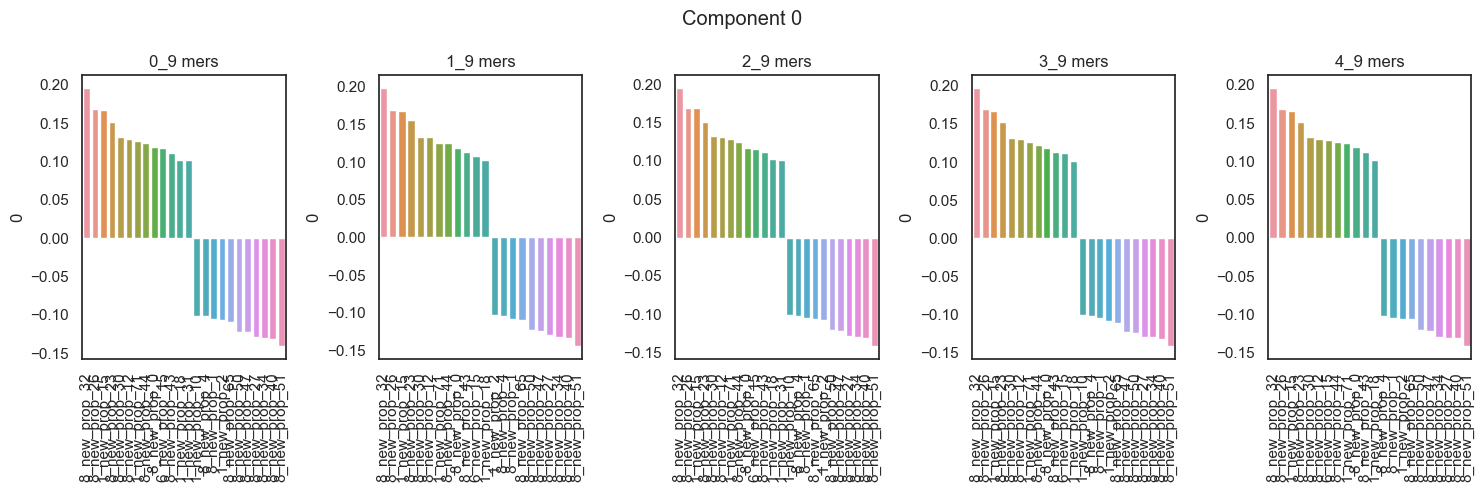

In [127]:


def plot_component(components_df,component_num, ax):
    T_components = components_df.T.sort_values(by=component_num, ascending=False)
    T_components = T_components[(T_components[component_num] > 0.1) | (T_components[component_num] < -0.1)]
    ax = sns.barplot(data =T_components, x=T_components.index, y=component_num, ax=ax)
    ax.tick_params(axis='x', rotation=90)
    return ax
fig, axes = plt.subplots(ncols=len(subsets), figsize=(15, 5))

component_num = 0

for i, key in enumerate(subsets):
    plot_component(per_size_component_df[key], component_num, axes[i]).set_title(f"{key} mers")   
fig.suptitle(f"Component {component_num}")
plt.tight_layout()
 

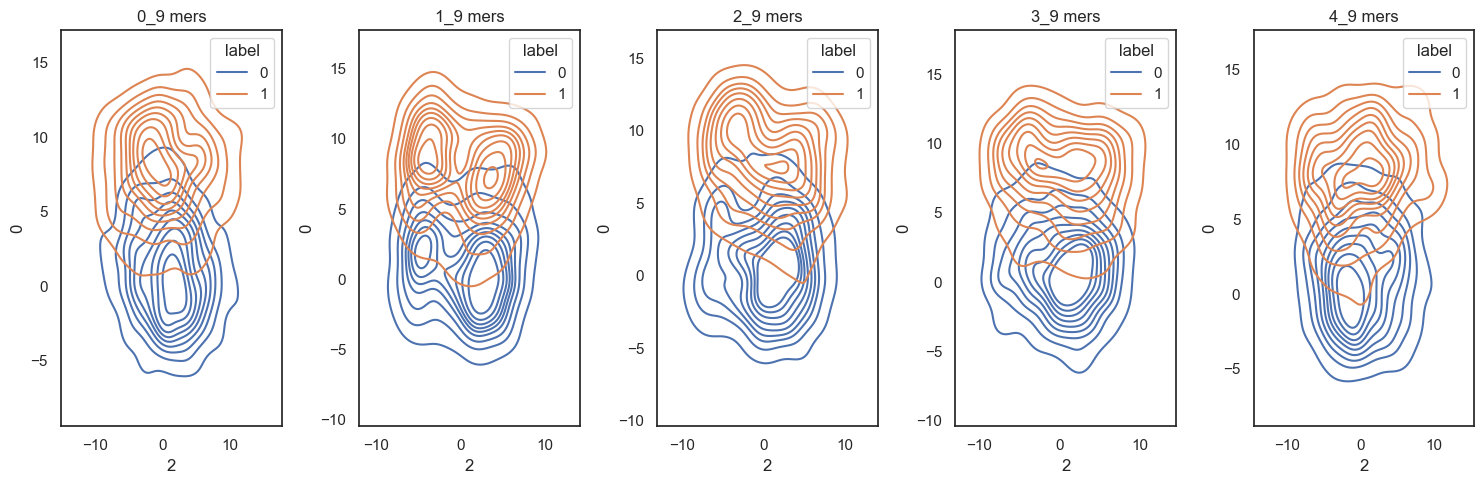

In [128]:
fig, axes = plt.subplots(ncols=len(subsets), figsize=(15, 5))

x=2
y=0
for i, key in enumerate(subsets):
    tr_df1 = per_size_transformed_df[key]
    sns.kdeplot(data=tr_df1, x=x , y=y, hue='label', ax = axes[i]).set_title(f"{key} mers")

plt.tight_layout()

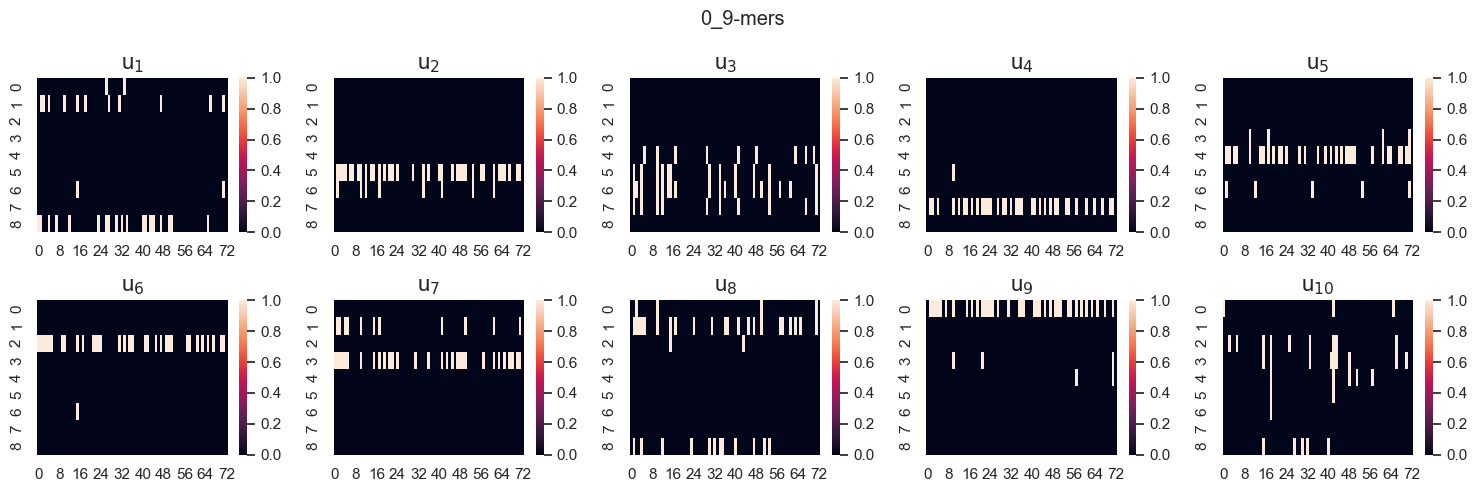

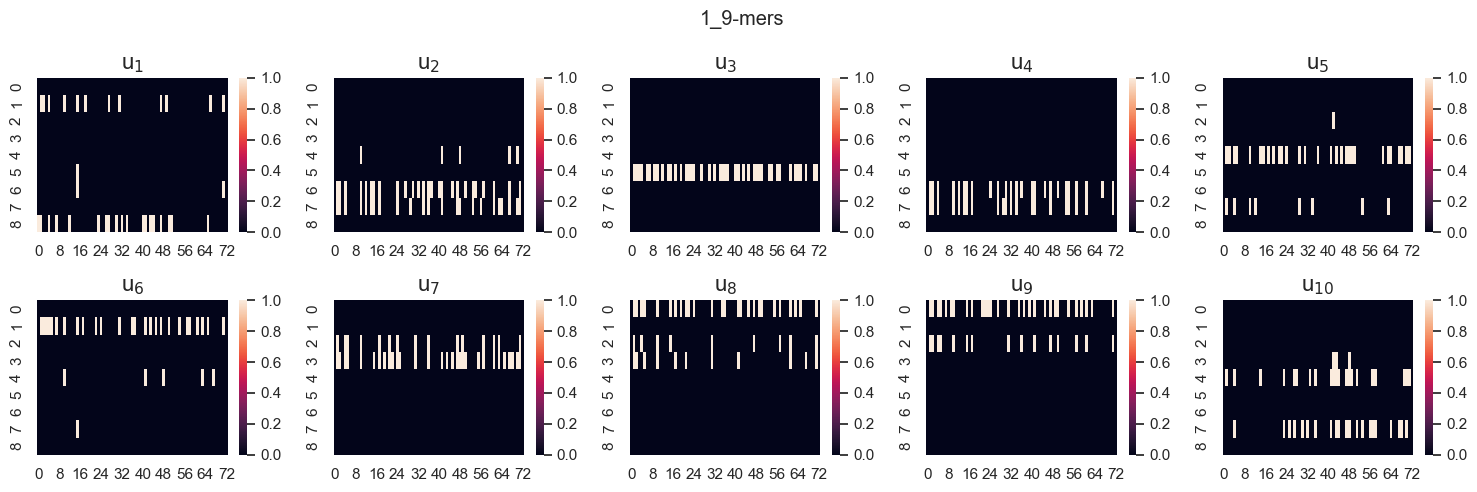

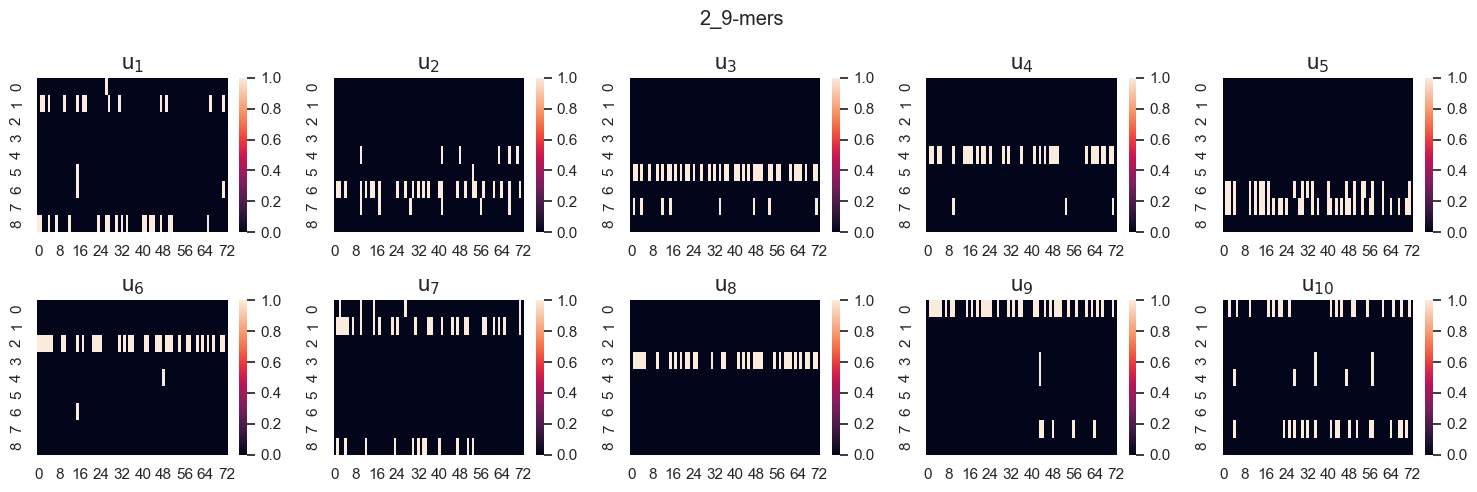

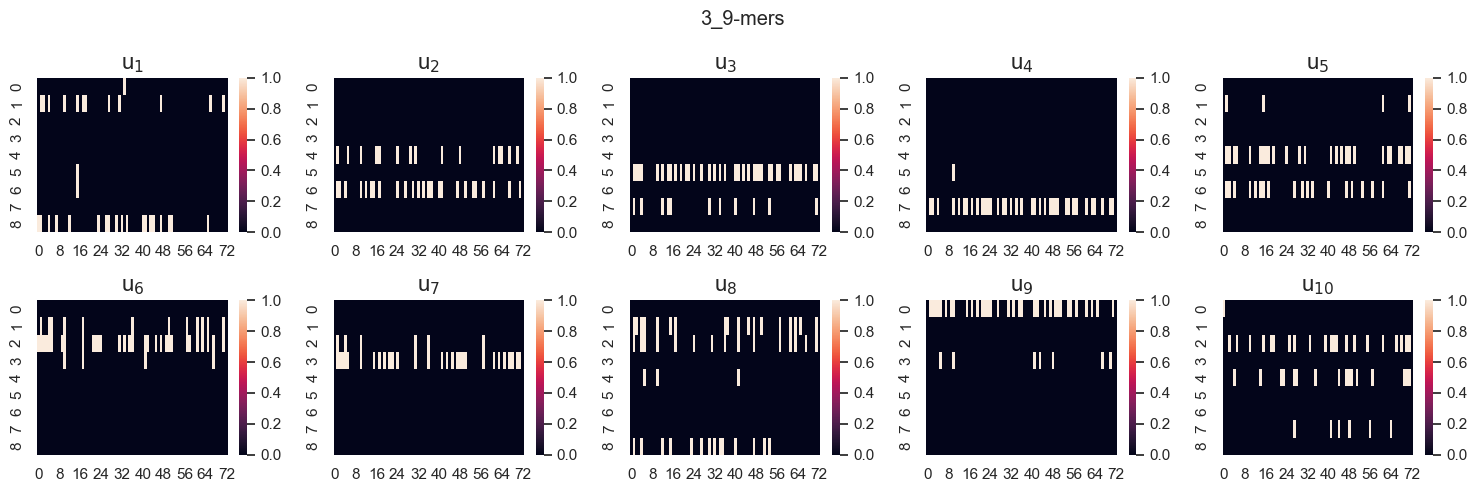

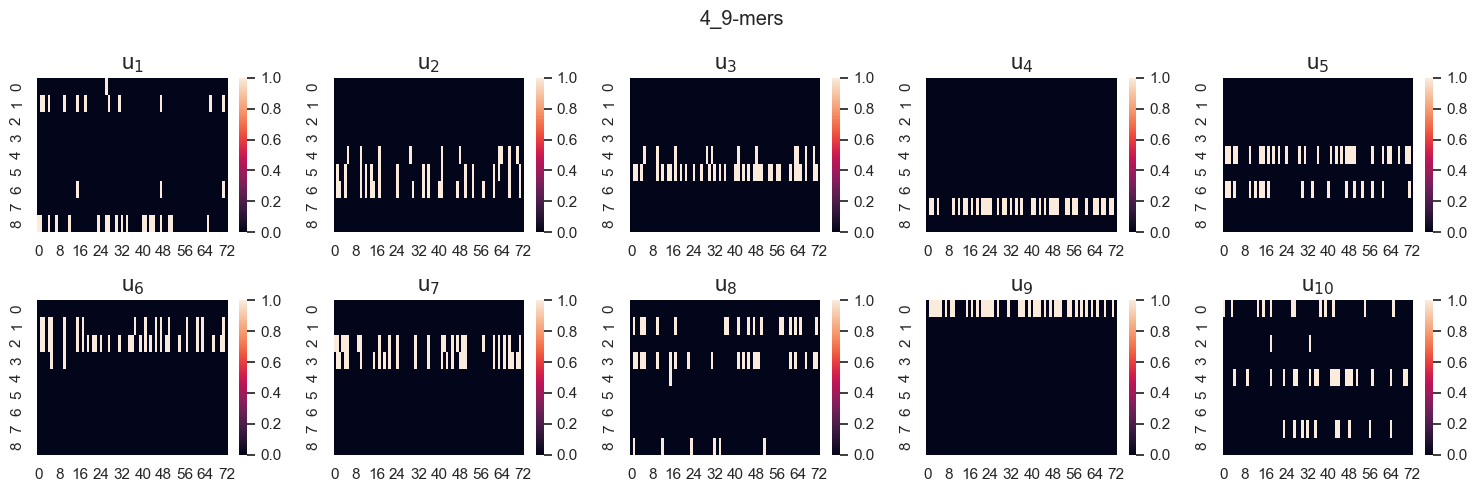

In [129]:
import matplotlib.pyplot as plt


def plot_u_vectors(total_dfs, key):
    df_to_analyze = per_size_data_df[key]
    U = per_size_component_matrix[key]

    nrows = int(len(U) / 2)

    fig, axes = plt.subplots( 2,nrows, figsize=(15,5))
    prop_nums = np.array(df_to_analyze.drop(columns=not_feature_columns, errors='ignore').columns.str.split('_').map(lambda x: x[-1]).unique().astype(int))
    threshold = None
    threshold = 0.08
    target_length = int(key.split("_")[1])


    for i, ax in enumerate(fig.axes):
        prop_position_matrix = np.zeros((target_length, max(prop_nums) + 1))

        for prop_name, value in zip(df_to_analyze.drop(columns=not_feature_columns).columns, U[i, :]):
            m_j = int(prop_name.split('_')[-1])
            m_i = int(prop_name.split('_')[0])
            prop_position_matrix[m_i][m_j] = value

        if threshold:
            df = (np.abs(prop_position_matrix) > threshold)
        else:
            df = prop_position_matrix
        sns.heatmap(df, ax=ax).set_title(f"u$_{{{i+1}}}$", fontsize=16)
        # axes[i // 4, i % 4].imshow(U[:, i].reshape((73,9)))
    fig.suptitle(f"{key}-mers")
    plt.tight_layout()

for i, key in enumerate(subsets):
    plot_u_vectors(total_dfs, key)


In [131]:
dfs = [pd.DataFrame(per_size_component_matrix[key], columns=per_size_data_df[key].drop(columns=not_feature_columns).columns)
       for key in subsets]


In [133]:
concat_df = pd.concat(dfs).reset_index(drop=True)
corr_df = concat_df.T.corr()

Text(0.5, 1.0, 'correlation of U vectors')

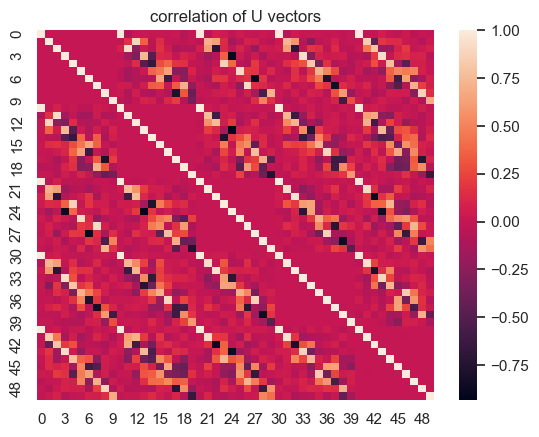

In [134]:
sns.heatmap(corr_df).set_title(f"correlation of U vectors")

Text(0.5, 1.0, 'Abs correlation of U vectors with threshold 0.6')

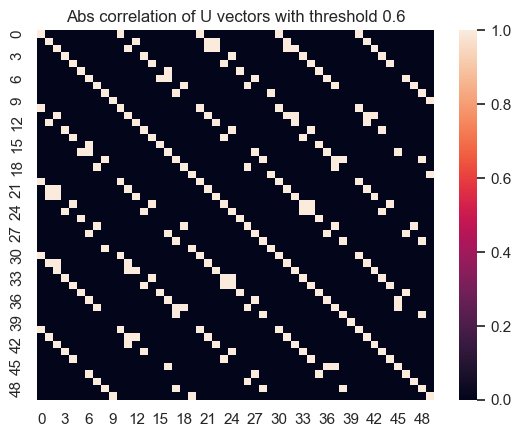

In [135]:
threshold = 0.6
sns.heatmap(corr_df.abs() > threshold).set_title(f"Abs correlation of U vectors with threshold {threshold}")

# Some old analysis we leave here

## Analyze selected properties and coefficients for them

In [256]:

component1 = 1
T_components = components_df.T.sort_values(by=component1, ascending=False)
# props1 = ['new_prop_32', 'new_prop_15', 'new_prop_26','new_prop_0']
props1 =  T_components[(T_components[component1] > 0.1) | (T_components[component1] < -0.1)].index.str.split('_', 1).map(lambda x:x[1]).unique().tolist()
component2 = 0
# props2 = ['new_prop_67', 'new_prop_56', 'new_prop_10', ]
props2 = T_components[(T_components[component2] > 0.1) | (T_components[component2] < -0.1)].index.str.split('_', 1).map(lambda x:x[1]).unique().tolist()

total_props = set(props1).union(set(props2))


x_prop = props1[0]
y_prop = props1[1]


C:\Users\denkl\AppData\Local\Temp\ipykernel_7204\2417841126.py:4: FutureWarning: In a future version of pandas all arguments of StringMethods.split except for the argument 'pat' will be keyword-only.
  props1 =  T_components[(T_components[component1] > 0.1) | (T_components[component1] < -0.1)].index.str.split('_', 1).map(lambda x:x[1]).unique().tolist()
C:\Users\denkl\AppData\Local\Temp\ipykernel_7204\2417841126.py:7: FutureWarning: In a future version of pandas all arguments of StringMethods.split except for the argument 'pat' will be keyword-only.
  props2 = T_components[(T_components[component2] > 0.1) | (T_components[component2] < -0.1)].index.str.split('_', 1).map(lambda x:x[1]).unique().tolist()


In [257]:
props1

['new_prop_53',
 'new_prop_71',
 'new_prop_1',
 'new_prop_34',
 'new_prop_17',
 'new_prop_4',
 'new_prop_41',
 'new_prop_15',
 'new_prop_57',
 'new_prop_47',
 'new_prop_49',
 'new_prop_40',
 'new_prop_36',
 'new_prop_24',
 'new_prop_64',
 'new_prop_56',
 'new_prop_45',
 'new_prop_30',
 'new_prop_21',
 'new_prop_50',
 'new_prop_2',
 'new_prop_67',
 'new_prop_14',
 'new_prop_61',
 'new_prop_12',
 'new_prop_10']

In [258]:
props2

['new_prop_27',
 'new_prop_51',
 'new_prop_40',
 'new_prop_50',
 'new_prop_34',
 'new_prop_47',
 'new_prop_65',
 'new_prop_1',
 'new_prop_4',
 'new_prop_15',
 'new_prop_44',
 'new_prop_0',
 'new_prop_43',
 'new_prop_12',
 'new_prop_30',
 'new_prop_26',
 'new_prop_23',
 'new_prop_32']

In [259]:
from collections import defaultdict
coefs = dict()
i=0
for component_num in range(len(components_df)):
    coefs[component_num] = dict()
    for pos in range(9):
        coefs[component_num][pos] = defaultdict(float)
        for  feat, coef in components_df.iloc[component_num].items():
            if feat.startswith(str(pos)) and feat.split('_', 1)[1] in total_props:
                coefs[component_num][pos][feat.split('_', 1)[1]] = coef


In [260]:
# plot 1 pair
values1 = new_prop_index[props1]
values2 =  new_prop_index[props2]

def plot_aas(values, scale=0.1, textsize='medium',leg=True, column1=0, column2=1):
    x_prop = values.columns[column1]
    y_prop = values.columns[column2]
    print(f"props will be {x_prop} and {y_prop}")
    ax = sns.scatterplot(values, x=x_prop, y=y_prop, hue=values.index)
    for line in range(0,values.shape[0]):
        plt.text(values[x_prop][line]+scale, values[y_prop][line], values.index[line], horizontalalignment='left', size=textsize, color='black', weight='semibold')
    if leg:
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)
    else:
        ax.legend().set_visible(False)


props will be new_prop_53 and new_prop_71


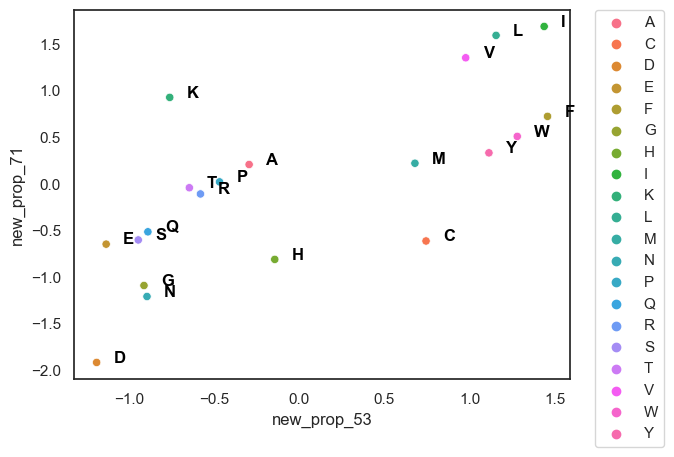

In [261]:
plot_aas(values1)

props will be new_prop_27 and new_prop_51


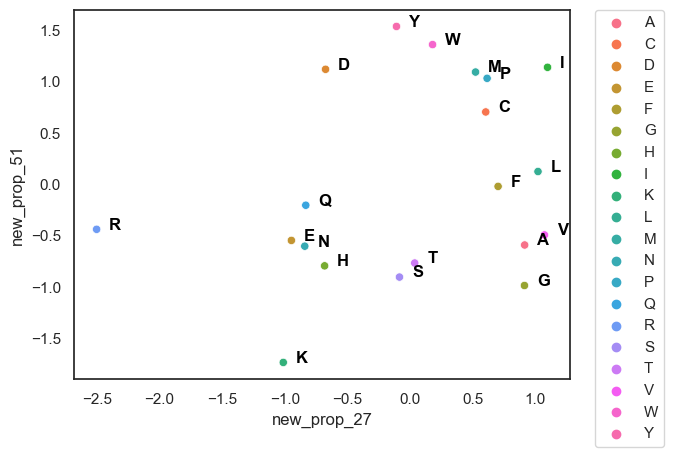

In [262]:
plot_aas(values2)

In [263]:


dfs = list()
for pos in range(9):
    df_for_pos = pd.DataFrame()

    df_for_pos[f"comp{component1}"] = sum( values1[props1[i]] * coefs[component1][pos][props1[i]] for i in range(len(props1)))
    df_for_pos[f"comp{component2}"] = sum(values2[props2[i]] * coefs[component2][pos][props2[i]]  for i in range(len(props2)))
    df_for_pos.index = values1.index.values + f"_{pos}"
    dfs.append(df_for_pos)
df_new = pd.concat(dfs)




In [264]:
df_new

,comp1,comp0
A_0,-0.048201,0.331440
C_0,0.016205,-0.358033
D_0,0.188929,-0.024480
E_0,0.056271,0.206265
F_0,-0.138335,-0.163233
...,...,...
S_8,0.002444,0.084808
T_8,0.041366,-0.227611
V_8,0.126496,-1.301834
W_8,0.105859,-1.218751


props will be comp1 and comp0


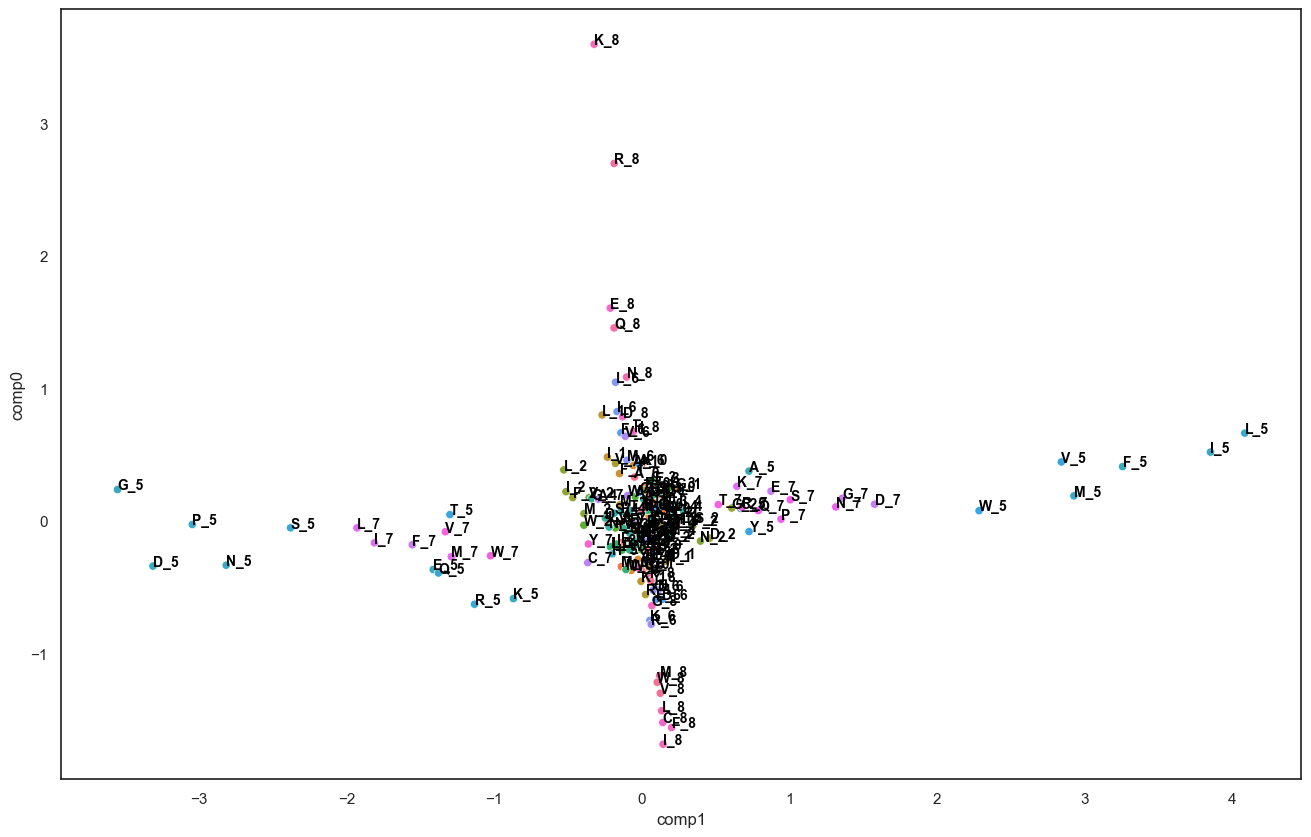

In [265]:

plt.figure(figsize=(16,10))
plot_aas(df_new, scale=0, textsize='small', leg=False)


In [297]:
component_formula = list()
for i in range(len(algo_object.components_)):

    component_formula =" ".join([
        "%+0.3f * %s" % (coef, feat)
        for feat, coef in components_df.iloc[i].items() if coef > 0.1 or coef < -0.1
    ])

    print(f"{i}: \n\t{component_formula}")



0: 
	+0.132 * 8_new_prop_0 -0.117 * 8_new_prop_1 -0.108 * 8_new_prop_4 +0.144 * 8_new_prop_12 +0.132 * 1_new_prop_15 +0.108 * 6_new_prop_15 +0.170 * 8_new_prop_23 +0.194 * 8_new_prop_26 -0.135 * 8_new_prop_27 +0.140 * 8_new_prop_30 +0.217 * 8_new_prop_32 -0.141 * 8_new_prop_34 -0.140 * 8_new_prop_40 +0.101 * 8_new_prop_41 +0.129 * 8_new_prop_43 +0.133 * 8_new_prop_44 -0.132 * 8_new_prop_47 -0.146 * 8_new_prop_50 -0.161 * 8_new_prop_51 -0.131 * 8_new_prop_65
1: 
	-0.147 * 6_new_prop_1 +0.110 * 6_new_prop_2 -0.135 * 6_new_prop_4 -0.132 * 4_new_prop_5 +0.152 * 4_new_prop_10 +0.148 * 6_new_prop_10 +0.139 * 6_new_prop_12 +0.123 * 6_new_prop_14 -0.143 * 6_new_prop_15 +0.118 * 4_new_prop_16 -0.125 * 4_new_prop_17 -0.127 * 6_new_prop_17 +0.124 * 4_new_prop_29 -0.138 * 6_new_prop_34 -0.113 * 6_new_prop_40 -0.172 * 4_new_prop_41 -0.117 * 6_new_prop_41 -0.129 * 6_new_prop_47 -0.189 * 4_new_prop_48 +0.116 * 6_new_prop_50 -0.149 * 6_new_prop_53 -0.107 * 6_new_prop_57 +0.100 * 4_new_prop_60 +0.140 *

# Check classifictation

In [190]:
result_df

,0,1,2,3,4,5,6,7,8,9,label
0,8.688153,1.668422,-6.549500,0.350852,-2.847579,-9.345014,-6.894373,3.474700,0.985806,5.300561,1
1,8.727552,9.192994,-4.277740,-5.633777,5.071787,0.728778,-0.116492,0.788105,2.457777,-1.649580,2
2,13.410729,-7.706222,-4.328115,-0.491429,0.096180,1.112162,5.211936,-1.147376,-0.939653,3.022294,2
3,9.175763,0.297366,2.828843,6.544505,-1.672611,10.204616,4.378705,0.049892,-2.554520,3.130289,1
4,-2.803493,-1.376571,-2.929441,-6.206139,-2.266186,-1.533547,-3.560259,2.284281,4.173503,-1.283216,2
...,...,...,...,...,...,...,...,...,...,...,...
1995,11.051725,-0.876536,-6.910223,3.025944,-0.533589,-1.973666,-2.806904,-1.888420,0.745585,-0.554652,1
1996,9.988862,0.087179,-5.933412,-5.126738,-5.179374,5.286484,1.088852,-1.658683,-4.934183,-2.268377,2
1997,4.158757,2.697443,4.769175,-4.550370,2.065984,1.327135,4.857507,-3.189952,-4.262610,-3.127069,2
1998,7.400319,-2.202224,-2.463339,3.462728,1.695918,-1.817486,0.209532,-4.376628,5.228433,-3.114500,1


In [193]:
from sklearn import svm
from sklearn.model_selection import train_test_split
from sklearn  import tree


df = result_df[result_df.label.isin([1,2])]
X = df.drop(columns=['label'])

y = df['label'].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=42
)


clf = svm.SVC(kernel='linear', C=1).fit(X_train, y_train)
# clf = tree.DecisionTreeClassifier().fit(X_train, y_train)
clf.score(X_test, y_test)

0.62875

In [192]:
df_to_analyze[['peptide', 'allele']].reset_index(drop=True).to_csv('C://Sandbox/peptides_for_classification.csv')

In [108]:
df_to_analyze.tail()

,peptide,src_peptide,src_len,allele,0_new_prop_0,1_new_prop_0,2_new_prop_0,3_new_prop_0,4_new_prop_0,5_new_prop_0,...,0_new_prop_72,1_new_prop_72,2_new_prop_72,3_new_prop_72,4_new_prop_72,5_new_prop_72,6_new_prop_72,7_new_prop_72,8_new_prop_72,label
0,SSSTVSYLK,SSSTVSYLK,9,HLA-A*11:01,-0.859429,-0.859429,-0.859429,-0.781533,-0.718115,-0.859429,...,1.187566,1.187566,1.187566,1.419912,1.586752,1.187566,0.054447,-0.380958,-0.562186,2
0,ATALEYVYK,ATALEYVYK,9,HLA-A*11:01,-1.429296,-0.781533,-1.429296,-0.229879,0.107572,0.949807,...,-1.209077,1.419912,-1.209077,-0.380958,-1.250244,0.054447,1.586752,0.054447,-0.562186,2
0,VGYYTFHPK,VGYYTFHPK,9,HLA-A*11:01,-0.718115,-1.732990,0.949807,0.949807,-0.781533,0.633390,...,1.586752,0.463100,0.054447,0.054447,1.419912,-0.210342,0.579846,-0.953390,-0.562186,2
0,ASFAFEFPK,ASFAFEFPK,9,HLA-A*11:01,-1.429296,-0.859429,0.633390,-1.429296,0.633390,0.107572,...,-1.209077,1.187566,-0.210342,-1.209077,-0.210342,-1.250244,-0.210342,-0.953390,-0.562186,2
0,EISSNDNAK,EISSNDNAK,9,HLA-A*11:01,0.107572,-0.113714,-0.859429,-0.859429,-0.164471,-0.478462,...,-1.250244,0.581464,1.187566,1.187566,0.929424,-0.256526,0.929424,-1.209077,-0.562186,2


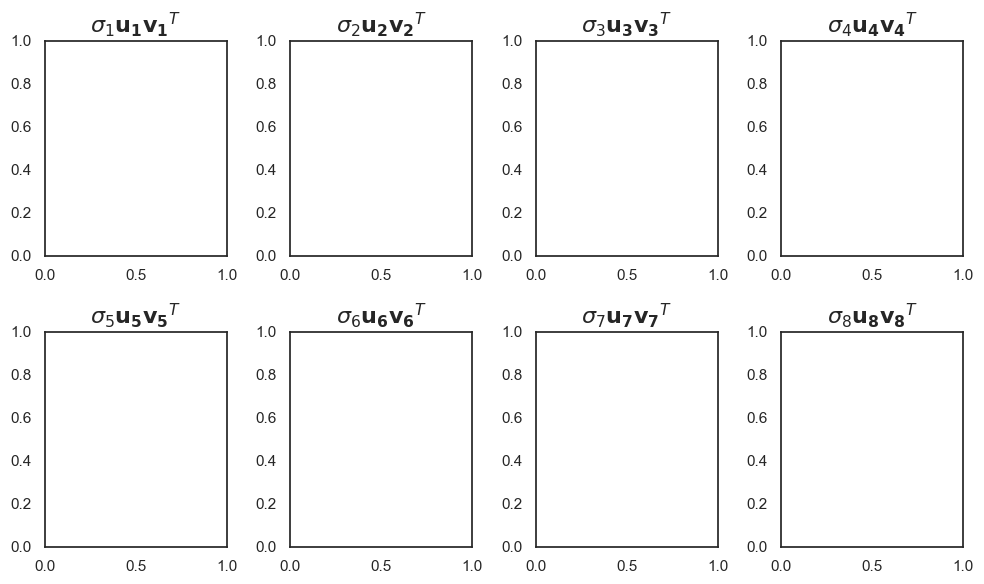

In [205]:
# Analyze V matrix


fig, axes = plt.subplots(2, 4, figsize=(10,6))

threshold = None
threshold = 0.07
for i in range(0, 8):
    mat_i = s[i] * U[:,i].reshape(-1,1) @ VT[i,:].reshape(1,-1)

    mat_i = mat_i


    # axes[i // 4, i % 4].imshow(U[:, i].reshape((73,9)))

    axes[i // 4, i % 4].set_title("$\sigma_{0}\mathbf{{u_{0}}}\mathbf{{v_{0}}}^T$".format(i+1), fontsize=16)
plt.tight_layout()
plt.show()

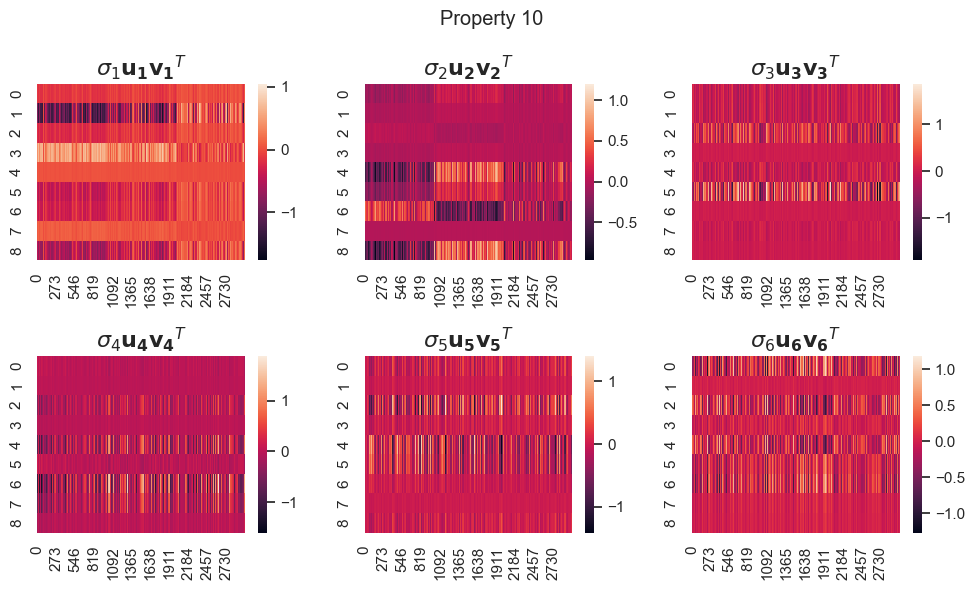

In [426]:
selected_pos = 1
fig, axes = plt.subplots(2, 3, figsize=(10,6))
plt.subplots_adjust(wspace=0.3, hspace=0.05)

sel_property = 10
for i in range(0, 6):
    mat_i = s[i] * U[:,i].reshape(-1,1) @ VT[i,:].reshape(1,-1)
    mat_i = mat_i[sel_property::73]
    # mat_i = np.sort(mat_i, axis=1)
    sns.heatmap(mat_i, ax =axes[i // 3, i % 3])
    #mat_i[mat_i < 1e-8] = 0
    # axes[i // 3, i % 3].imshow(mat_i)
    axes[i // 3, i % 3].set_title("$\sigma_{0}\mathbf{{u_{0}}}\mathbf{{v_{0}}}^T$".format(i+1), fontsize=16)
plt.suptitle(f"Property {sel_property}")
plt.tight_layout()
#
# plt.show()

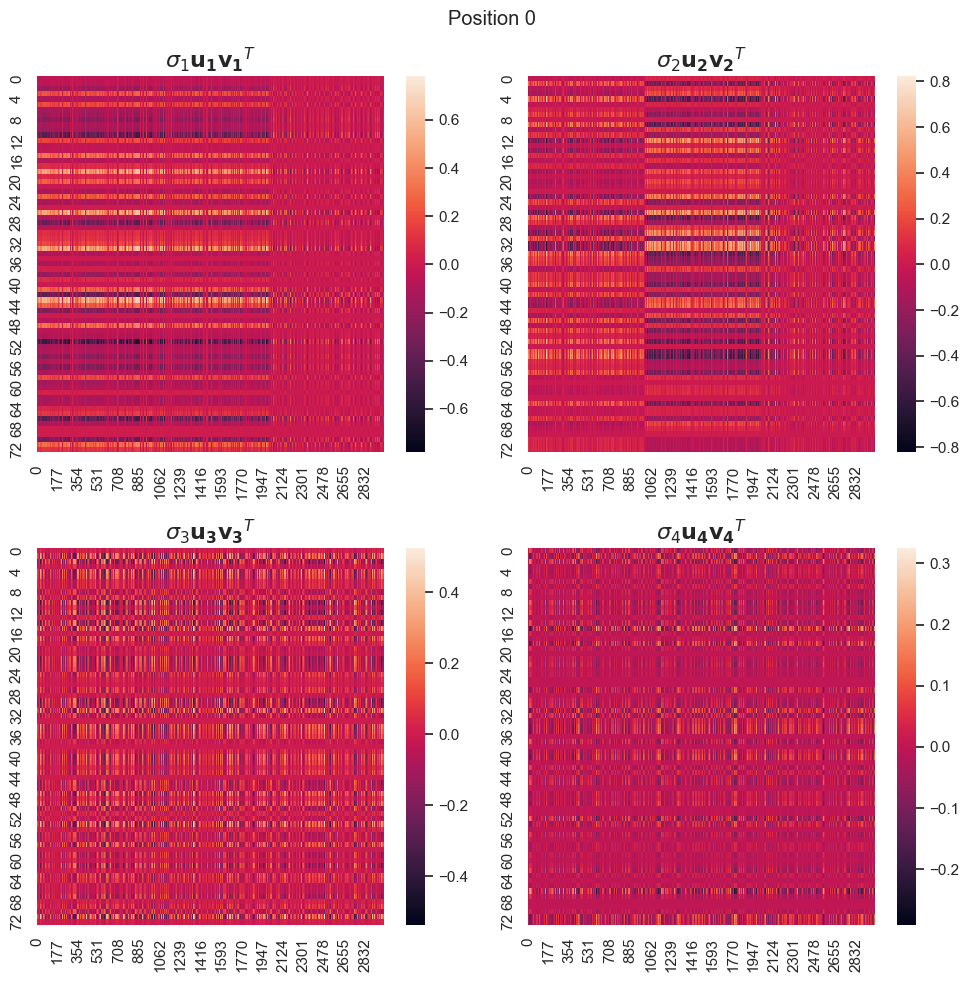

In [451]:
selected_pos = 0
fig, axes = plt.subplots(2, 2, figsize=(10,10))
plt.subplots_adjust(wspace=0.3, hspace=0.05)

sel_property = 10
for i in range(0, 4):
    mat_i = s[i] * U[:,i].reshape(-1,1) @ VT[i,:].reshape(1,-1)
    mat_i = mat_i[selected_pos*73:(selected_pos+1)*73:]
    # mat_i = np.sort(mat_i, axis=1)
    sns.heatmap(mat_i, ax =axes[i // 2, i % 2])
    #mat_i[mat_i < 1e-8] = 0
    # axes[i // 3, i % 3].imshow(mat_i)
    axes[i // 2, i % 2].set_title("$\sigma_{0}\mathbf{{u_{0}}}\mathbf{{v_{0}}}^T$".format(i+1), fontsize=16)
plt.suptitle(f"Position {selected_pos}")
plt.tight_layout()
#

In [455]:
selected_pos = 0
fig, axes = plt.subplots(2, 2, figsize=(10,10))
plt.subplots_adjust(wspace=0.3, hspace=0.05)

sel_property = 10
for i in range(0, 4):
    mat_i = VT
    #mat_i = mat_i[selected_pos*73:(selected_pos+1)*73:]
    # mat_i = np.sort(mat_i, axis=1)
    sns.heatmap(mat_i, ax =axes[i // 2, i % 2])
    #mat_i[mat_i < 1e-8] = 0
    # axes[i // 3, i % 3].imshow(mat_i)
    axes[i // 2, i % 2].set_title("$\sigma_{0}\mathbf{{u_{0}}}\mathbf{{v_{0}}}^T$".format(i+1), fontsize=16)
plt.tight_layout()
#

Error in callback <function flush_figures at 0x00000192CD219940> (for post_execute):


KeyboardInterrupt: 

C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\seaborn\matrix.py:657: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


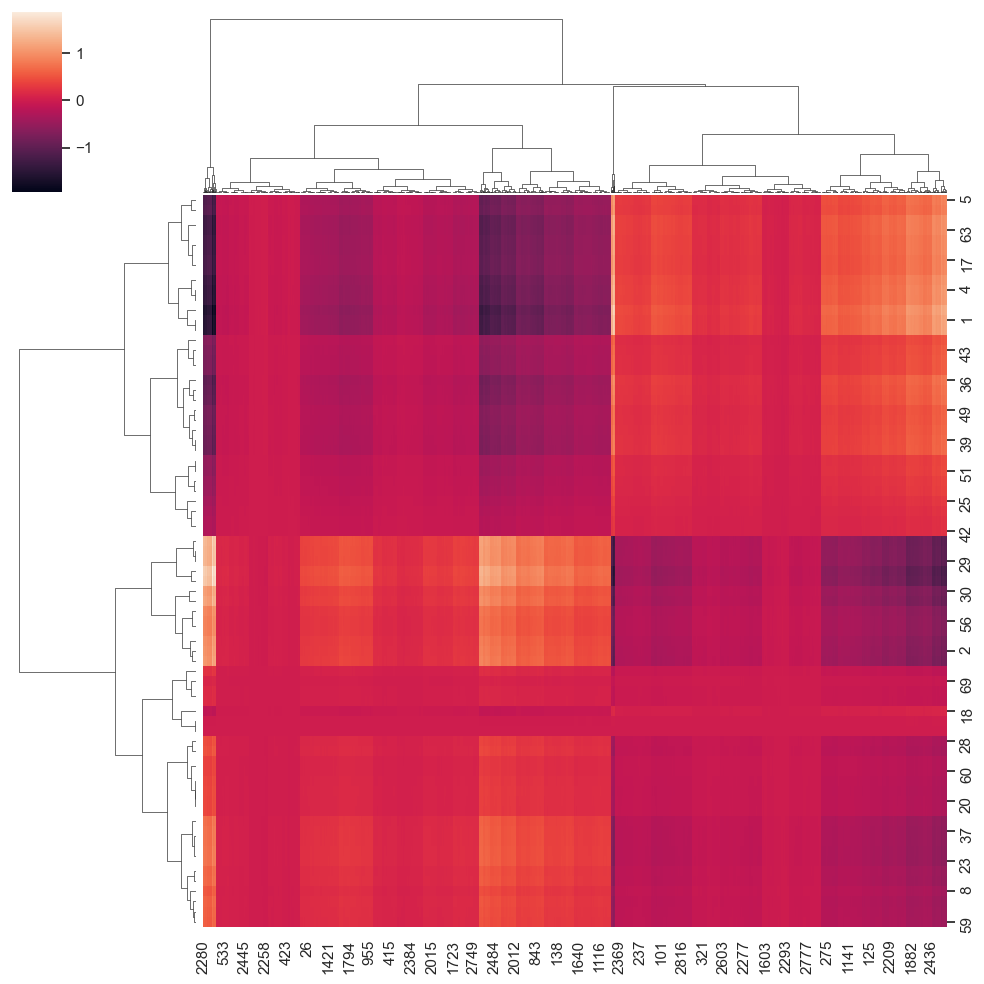

In [449]:
sns.clustermap(mat_i)

In [407]:
mat_i[::73]

array([[ 0.08727249, -0.14327756,  0.02050001, ...,  0.01794225,
         0.02807837, -0.07951413]])

<AxesSubplot: >

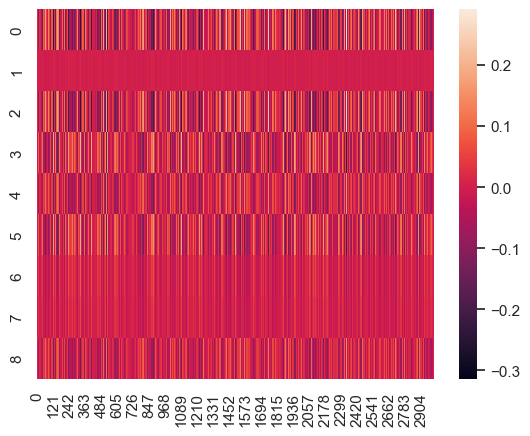

In [409]:
sns.heatmap(mat_i)

## Feature importance

## Get decoy data

In [16]:
from mhcgnomes import parse
# decoy data
def defineOrganism(allele_name):
    parse_result = parse(allele_name)
    if parse_result.is_mouse:
        return "Mouse"
    elif parse_result.is_human:
        return "Human"
    else:
        print("organism not found")
        return None

def defineClass(allele_name):
    parse_result = parse(allele_name)
    if parse_result.has_mhc_class:
        if parse_result.is_class1:
            return 'I'
        elif parse_result.is_class2:
            return 'II'
        else:
            print("Not class I or class II???!")
    else:
        print("Result without class")
    return None

per_allele_decoy_peptides = dict()
for allele_name in ALLELES:
    organism =  defineOrganism(allele_name).lower()
    class_to_use = defineClass(allele_name)
    DECOY_DATA_PATH = f"{DATA_PATH_BASE}\decoy\sampled_decoy_data_{organism}_class_{class_to_use}.csv"
    decoy_df =  pd.read_csv(DECOY_DATA_PATH)
    decoy_df['length'] = decoy_df['peptide'].str.len()
    per_allele_decoy_peptides[allele_name] = decoy_df.copy()[decoy_df['length'].isin(TARGET_LENGTHS)]['peptide'].values

peptides_for_analysis = np.unique(np.concatenate([value for key, value in per_allele_decoy_peptides.items()
                                                  if key in ALLELES]))

C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T


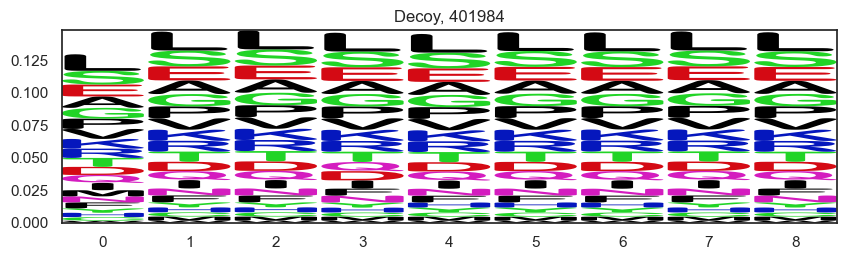

In [17]:
make_logo_for_data(peptides_for_analysis, "Decoy")

In [43]:
sampled_decoy = np.random.choice(peptides_for_analysis, len(peptides))
sampled_decoy2 = np.random.choice(peptides_for_analysis, len(peptides))

sampled_decoy2 = np.array( [item[0] + 'Y' + item[2:] for item in sampled_decoy2]) #sample Y

C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T


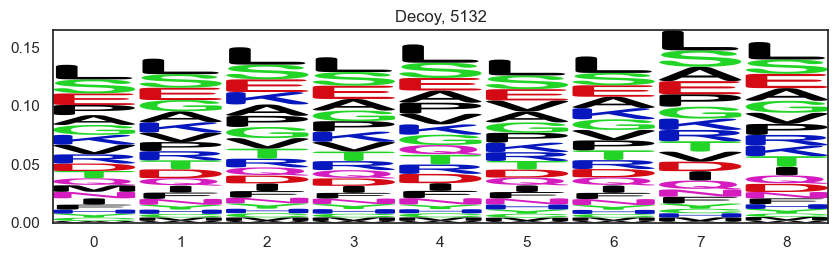

In [19]:
make_logo_for_data(sampled_decoy, "Decoy")

C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T


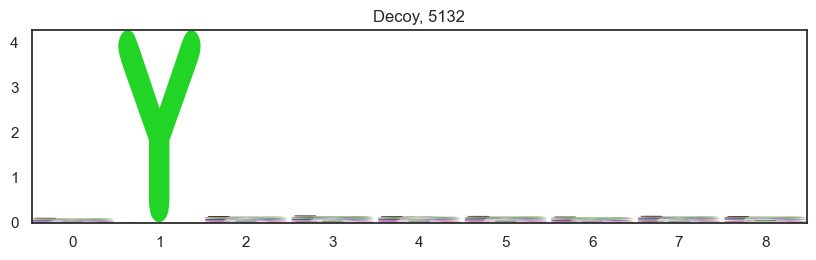

In [44]:
make_logo_for_data(sampled_decoy2, "Decoy")

In [57]:
from tqdm import tqdm

transformed_decoy = np.array([np.array([tuple(transform_dict[aa] for transform_dict in transform_dicts) for aa in peptide]) for peptide in sampled_decoy])
transformed_decoy2 = np.array([np.array([tuple(transform_dict[aa] for transform_dict in transform_dicts) for aa in peptide]) for peptide in sampled_decoy2])


In [58]:
# peptides1 = peptides
peptides1 = transformed_decoy
peptides2 = transformed_decoy2

In [59]:
from collections import defaultdict
selected_positions = [0, 1, 2, 3, 4, 5, 6, 7, 8]
selected_positions = [ 1]
position_to_selected_data = defaultdict(list)
position_to_selected_data_y = defaultdict(list)

for peptide in peptides1:
    for selected_position in selected_positions:
        position_to_selected_data[selected_position].append(peptide[selected_position])
        position_to_selected_data_y[selected_position].append(1)

for peptide in peptides2:
    for selected_position in selected_positions:
        position_to_selected_data[selected_position].append(peptide[selected_position])
        position_to_selected_data_y[selected_position].append(0)

In [60]:
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

result_selected_features = set()
total_selected_features = np.array(selected_properties)
for position in selected_positions:
    X = np.array(position_to_selected_data[position])
    y = np.array(position_to_selected_data_y[position])

    df_X = pd.DataFrame(X)
    corr_df = df_X.corr().abs()
    upper_tri = corr_df.where(np.triu(np.ones(corr_df.shape),k=1).astype(np.bool))
    to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.95)]
    uncorrelated_X = df_X.drop(df_X.columns[to_drop], axis=1)
    feature_names = total_selected_features[uncorrelated_X.columns.to_numpy()]
    X = uncorrelated_X.values

    # scaler = StandardScaler()
    # X = scaler.fit_transform(X)
    X, y = shuffle(X, y, random_state=0)
    X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42)
    forest = RandomForestClassifier(random_state=0)
    forest.fit(X_train, y_train)
    importances = forest.feature_importances_
    forest_importances = pd.Series(importances, index=feature_names).sort_values(ascending=False)
    result_selected_features.update(forest_importances[:10].index.values)

C:\Users\denkl\AppData\Local\Temp\ipykernel_18256\3480479628.py:15: DeprecationWarning: `np.bool` is a deprecated alias for the builtin `bool`. To silence this warning, use `bool` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.bool_` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  upper_tri = corr_df.where(np.triu(np.ones(corr_df.shape),k=1).astype(np.bool))


In [61]:
result_selected_features

{'AURR980119',
 'CIDH920101',
 'FASG760102',
 'KARS160111',
 'OOBM850103',
 'OOBM850104',
 'PALJ810116',
 'QIAN880127',
 'VASM830102',
 'VASM830103'}

In [63]:
len(result_selected_features)

10

In [64]:
len(result_selected_features)

10

In [65]:
forest_importances

OOBM850103    0.070000
FASG760102    0.060000
CIDH920101    0.060000
PALJ810116    0.051323
VASM830102    0.050000
                ...   
GEOR030105    0.000000
GEOR030104    0.000000
GEOR030103    0.000000
GEOR030102    0.000000
ZIMJ680104    0.000000
Length: 374, dtype: float64

In [66]:
forest_importances

OOBM850103    0.070000
FASG760102    0.060000
CIDH920101    0.060000
PALJ810116    0.051323
VASM830102    0.050000
                ...   
GEOR030105    0.000000
GEOR030104    0.000000
GEOR030103    0.000000
GEOR030102    0.000000
ZIMJ680104    0.000000
Length: 374, dtype: float64

Text(0.5, 1.0, 'Correlation of features')

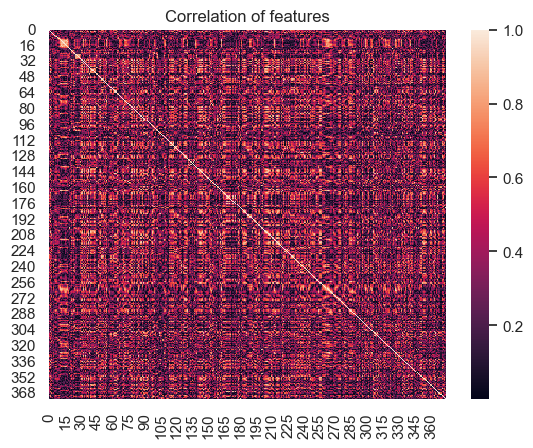

In [67]:
corr_df = pd.DataFrame(X).corr().abs()
ax = sns.heatmap(corr_df)
ax.set_title("Correlation of features")

In [135]:
df_corrr_result = result_X.corr().abs()

In [136]:
upper_tri = df_corrr_result.where(np.triu(np.ones(df_corrr_result.shape),k=1).astype(np.bool))

C:\Users\denkl\AppData\Local\Temp\ipykernel_12724\3515871676.py:1: DeprecationWarning: `np.bool` is a deprecated alias for the builtin `bool`. To silence this warning, use `bool` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.bool_` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  upper_tri = df_corrr_result.where(np.triu(np.ones(df_corrr_result.shape),k=1).astype(np.bool))


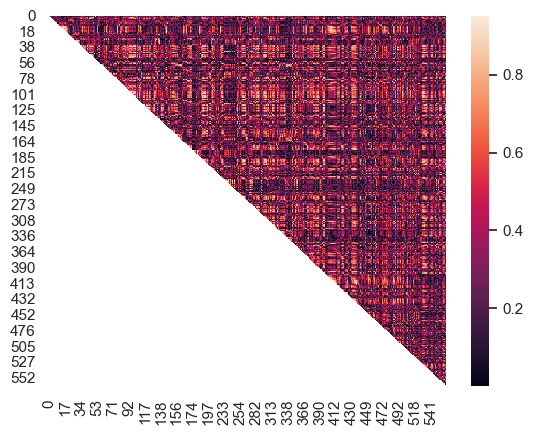

In [137]:
ax = sns.heatmap(upper_tri)

In [61]:
upper_tri = corr_df.where(np.triu(np.ones(corr_df.shape),k=1).astype(np.bool))

C:\Users\denkl\AppData\Local\Temp\ipykernel_12724\2619287707.py:1: DeprecationWarning: `np.bool` is a deprecated alias for the builtin `bool`. To silence this warning, use `bool` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.bool_` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  upper_tri = corr_df.where(np.triu(np.ones(corr_df.shape),k=1).astype(np.bool))


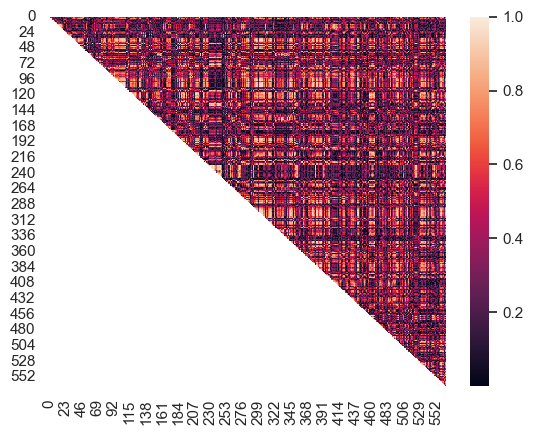

In [63]:
ax = sns.heatmap(upper_tri)

In [104]:
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.95)]
len(to_drop)

174

In [72]:
result_X = pd.DataFrame(X).drop(pd.DataFrame(X).columns[to_drop], axis=1)

In [73]:
result_X

,0,1,2,4,5,6,7,8,9,10,...,550,551,552,553,554,555,557,559,562,563
0,0.822547,0.459163,1.907089,-0.734838,0.721596,0.076803,0.265462,0.224131,-0.320055,0.311951,...,0.043679,0.204232,0.433801,1.109757,0.438773,0.378282,0.299054,0.908825,0.297605,-0.657229
1,-0.219428,-0.570157,-0.927142,2.418356,0.186292,0.776688,0.590645,0.059911,3.687350,3.016422,...,0.356621,0.404767,0.300436,0.036678,-0.704265,0.386878,-2.864230,-0.316301,-0.269909,1.438035
2,0.188302,-0.381690,-0.827501,0.871506,0.855422,-0.973025,-0.222312,-0.679081,0.109310,-0.106266,...,1.366572,-1.582889,-0.066319,-2.061789,-2.304518,-2.735388,0.486354,0.283041,-0.119560,1.528814
3,0.052392,-0.367192,0.257478,-0.377873,-0.215185,0.426745,-0.832029,-1.048577,0.252432,1.120504,...,-0.648587,0.499136,-2.133481,-0.034861,-0.083758,0.373124,-0.169195,-0.959713,-0.708249,-0.719045
4,0.052392,-0.367192,0.257478,-0.377873,-0.215185,0.426745,-0.832029,-1.048577,0.252432,1.120504,...,-0.648587,0.499136,-2.133481,-0.034861,-0.083758,0.373124,-0.169195,-0.959713,-0.708249,-0.719045
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10259,-0.763067,0.966574,2.527077,-0.318379,-1.419619,-0.098168,0.224814,-0.555916,-0.491801,-0.217790,...,-0.316679,-0.131959,0.833897,1.515143,1.679786,0.462528,0.351081,1.622748,1.388162,-0.713426
10260,0.097695,0.415670,-0.982498,0.157575,0.320118,-0.039845,-1.197859,-0.350640,0.195183,-0.524483,...,0.840260,-1.405946,0.433801,-0.177938,0.144849,0.352492,0.767303,-0.333929,0.183255,1.420743
10261,0.731941,-1.179050,0.024982,-1.865228,0.052466,-0.098168,0.997123,1.332619,-0.577674,-0.831175,...,-0.601172,0.782244,-0.199684,-0.297169,0.308141,0.285439,-0.699878,-0.933271,-1.138120,-0.646854
10262,0.822547,0.459163,1.907089,-0.734838,0.721596,0.076803,0.265462,0.224131,-0.320055,0.311951,...,0.043679,0.204232,0.433801,1.109757,0.438773,0.378282,0.299054,0.908825,0.297605,-0.657229


In [69]:
forest_importances.sort_values(ascending=False)

OOBM850103    0.070000
FASG760102    0.060000
CIDH920101    0.060000
PALJ810116    0.051323
VASM830102    0.050000
                ...   
GEOR030105    0.000000
GEOR030104    0.000000
GEOR030103    0.000000
GEOR030102    0.000000
ZIMJ680104    0.000000
Length: 374, dtype: float64

In [70]:
import time
import numpy as np
start_time = time.time()
importances = forest.feature_importances_
std = np.std([tree.feature_importances_ for tree in forest.estimators_], axis=0)
elapsed_time = time.time() - start_time

print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

Elapsed time to compute the importances: 0.016 seconds


In [71]:
std

array([0.01198279, 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.01057998, 0.        , 0.        ,
       0.        , 0.20815383, 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.00444887, 0.12048984,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.01594715, 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.00260703,
       0.        , 0.        , 0.11790083, 0.        , 0.08328015,
       0.        , 0.11935323, 0.        , 0.09949874, 0.        ,
       0.        , 0.01035481, 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.0050935 , 0.        ,
       0.14      , 0.        , 0.01337447, 0.        , 0.     

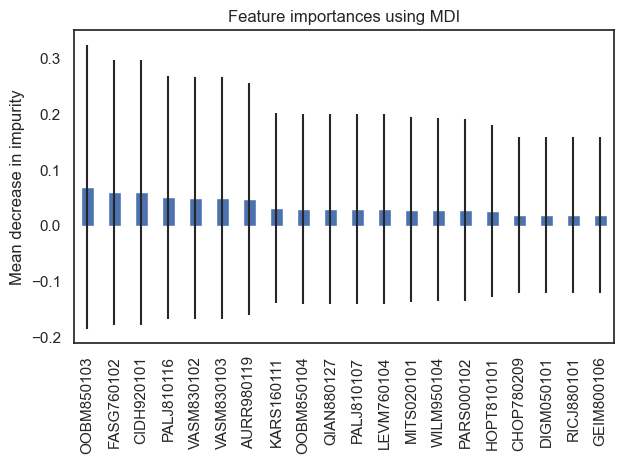

In [72]:
import pandas as pd
import matplotlib.pyplot as plt
forest_importances = pd.Series(importances, index=feature_names)
df = pd.DataFrame({"importances": importances, "std": std}, index=feature_names)
fig, ax = plt.subplots()

df = df.sort_values(by='importances', ascending=False)[:20]
df['importances'].plot.bar(yerr=df['std'], ax=ax)

# forest_importances.sort_values(ascending=False)[:20].plot.bar(yerr=std, ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

In [73]:
df

,importances,std
OOBM850103,0.070000,0.255147
FASG760102,0.060000,0.237487
CIDH920101,0.060000,0.237487
PALJ810116,0.051323,0.218039
VASM830102,0.050000,0.217945
VASM830103,0.050000,0.217945
AURR980119,0.047753,0.208154
KARS160111,0.031821,0.171228
OOBM850104,0.030000,0.170587
QIAN880127,0.030000,0.170587


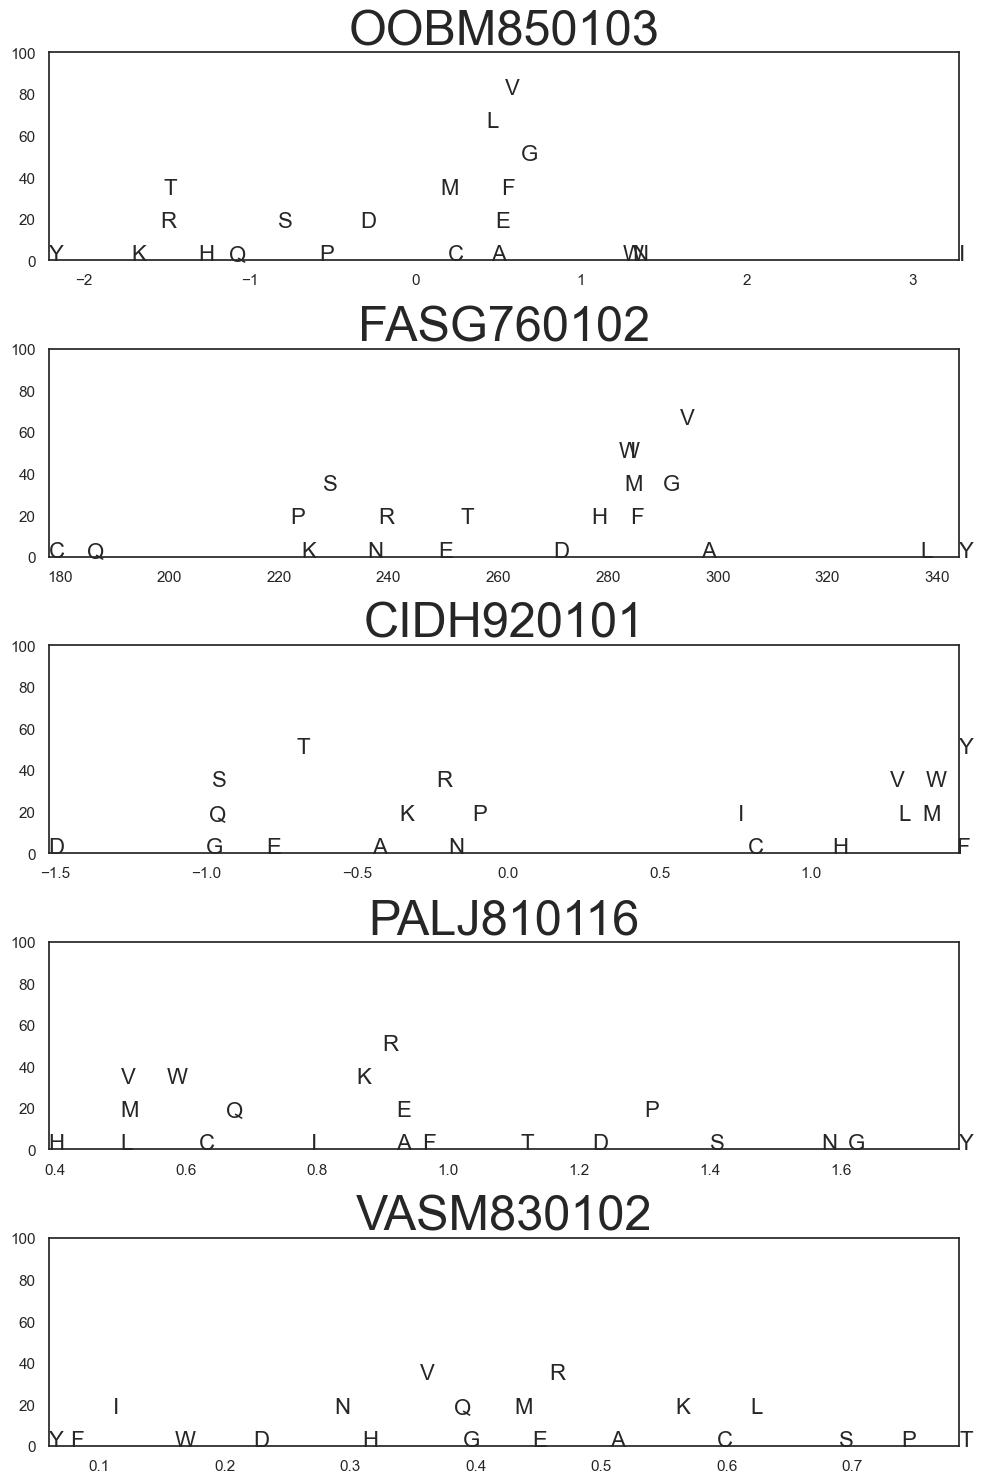

In [74]:
top_10_best = df[:5].index.values
from collections import defaultdict
import matplotlib.pyplot as plt
fig, axes = plt.subplots(ncols=1, nrows=len(top_10_best), figsize=(10, len(top_10_best)* 3))
for i, prop_id in enumerate(top_10_best):
    ax = axes[i]
    transform_dict = aaindex[prop_id]['values']
    x_left = min(transform_dict.values())
    x_right = max(transform_dict.values())
    std_value = np.std(list(transform_dict.values()))
    ax.set_xlim(x_left, x_right)
    ax.set_ylim(0, 100)

    # x = np.linspace(x_left, x_right, 1000)
    # y1= [1 for item in x]
    # axes[i].plot(x, y1, 'r', lw=2, label=f'result')

    scale_value_y = 16
    scale_value_x = std_value/3
    aa_to_x_position = dict()
    x_position_bin_to_aa = defaultdict(list)
    for aa,prop_value in transform_dict.items():
        aa_to_x_position[aa] = prop_value
    aa_to_y_position = dict()
    for aa,x_pos in aa_to_x_position.items():
        x_position_bin_to_aa[int(x_pos/scale_value_x)].append(aa)
    for bin, aas in x_position_bin_to_aa.items():
        for j, aa in enumerate(aas):
            aa_to_y_position[aa] = scale_value_y*j
    for aa,prop_value in transform_dict.items():
        ax.text(aa_to_x_position[aa], aa_to_y_position[aa], aa, fontsize=16 )

    ax.set_title(prop_id, fontsize=35)
plt.tight_layout()

# Permutation importance

In [288]:
from sklearn.inspection import permutation_importance

In [289]:
result = permutation_importance(
    forest, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2
)

In [290]:
forest_importances = pd.Series(result.importances_mean, index=feature_names)

<AxesSubplot:>

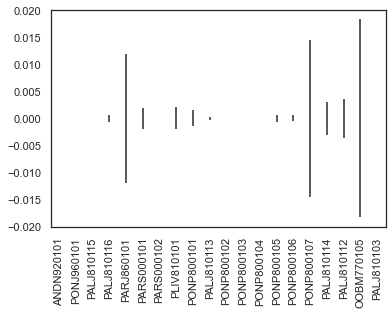

In [291]:
df = pd.DataFrame({"importances": result.importances_mean, "std": std}, index=feature_names)
fig, ax = plt.subplots()

df = df.sort_values(by='importances', ascending=False)[:20]
df['importances'].plot.bar(yerr=df['std'], ax=ax)

In [293]:
result

{'importances_mean': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 